# Libs

In [1]:
import sys
sys.path.append("../libs/")
sys.path.append("../")

In [2]:
import os
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import time
import gc
import math

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset, random_split
torch.manual_seed(42)

from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

import futurai_ppd as ppd
import futurai_utils as utils
from futurai_ml_dev import FuturaiML

DIR_DATA = os.getcwd() + "/data/"

# Load Data

In [3]:
process_name = "Compressor GARO"
timestamp="TIMESTAMP"

list_colomuns_drop = ['ARA-384R607M.PV', 'ARA-381P013B2.OP','ARA-384F934.PV','ARA-381I001H.PV','ARA-381I002H.PV','ARA-3385-FIC-522/PID1/PV.CV','ARA-3385-FI603/AI1/PV.CV','ARA-385F718.PV','ARA-381P013B.OP']

df_dataset = ppd.load_dataset_principal(DIR_DATA+process_name+".csv", list_colomuns_drop, timestamp, dropna=True, use_chunks=True, chunksize=10000)
df_dataset

,TIMESTAMP,ARA-384I607.PV,ARA-384V984.PV,ARA-384V985.PV,ARA-384T927.PV,ARA-384F922.PV,ARA-384F920.PV,ARA-384F920.OP,ARA-384P930.PV,ARA-384L924.PV,ARA-381P014B.PV,ARA-381P014B.OP,ARA-384P518.PV,ARA-381P013A.PV,ARA-381P013A.OP,ARA-384T671A.PV,ARA-384T671B.PV
0,2023-04-19 00:00:00,92.000000,5.306988,5.012907,42.011574,28.716339,148.415497,55.451496,552.904358,38.068817,1351.585938,-2.313365,546.095520,290.420624,17.450199,16.775427,5.000000
1,2023-04-19 00:01:00,92.000000,5.065593,5.195560,42.015404,28.729361,158.285156,54.648403,553.686157,38.122807,1344.595215,-2.480534,546.350342,302.940887,17.212788,16.873825,5.000000
2,2023-04-19 00:02:00,92.000000,5.347212,5.240568,42.033112,28.855486,143.562820,55.951195,553.137634,38.127640,1348.626343,-2.358739,546.263855,296.191681,17.352953,16.729815,5.000000
3,2023-04-19 00:03:00,92.000000,5.388839,5.122678,42.007809,28.726162,176.787521,53.388882,553.412537,37.910378,1356.204956,-2.182558,546.117615,286.139404,17.604618,16.897476,5.000000
4,2023-04-19 00:04:00,92.000000,5.555827,5.377805,42.021637,28.686049,168.841248,53.831390,553.172424,37.906616,1349.992310,-2.338447,546.158203,297.160034,17.554674,16.978853,5.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1446345,2026-01-26 07:46:00,93.480180,5.268874,3.344580,48.564632,28.943320,148.407883,60.612545,580.823853,38.111195,1356.614140,37.126694,547.464100,338.844452,0.486292,19.861310,9.778160
1446346,2026-01-26 07:47:00,93.519780,5.308822,3.369619,48.571823,28.947420,149.319885,60.624610,580.966900,38.109120,1350.809000,37.035282,547.082947,287.229370,1.613142,19.886950,9.787419
1446347,2026-01-26 07:48:00,93.559390,5.384368,3.400115,48.579018,28.951520,147.809372,60.636680,581.110000,38.107048,1351.822630,37.047330,546.701800,249.384171,2.868633,19.912592,9.796679
1446348,2026-01-26 07:49:00,93.598990,5.203719,3.322908,48.586210,28.955620,148.451248,60.615660,581.253052,38.104977,1350.281250,37.002876,546.320700,275.368439,2.236524,19.938232,9.805938


# Set ON/OFF var

In [4]:
pre_process = []
pp_var_ref_desligado = "ARA-384I607.PV"
pp_valor_ref_desligado = 30  
pp_tempo_ref_desligado = 0
pp_pre_corte_transitorio = 60 
pp_pos_corte_transitorio = 140
pre_process.append(  
{
   "after_cut": pp_pos_corte_transitorio,
   "interval_off": pp_tempo_ref_desligado,
   "limit_off": pp_valor_ref_desligado,
   "pre_cut": pp_pre_corte_transitorio,
   "variable_off": pp_var_ref_desligado
  })

# TAGs and descriptions

In [5]:
df_sistema, df_sistema_drop =  ppd.set_tags_config(df_dataset,DIR_DATA+process_name+"_subsistema.csv")
df_sistema

,VARIAVEL,DESC,SISTEMA,IQR,Q3
0,ARA-384I607.PV,CORRENTE COMPRESSOR GARO,GARO,1.000000,93.000000
1,ARA-384V984.PV,VIBRAÇÃO COMPR. GARO LA,GARO,0.642314,4.680895
2,ARA-384V985.PV,VIBRAÇÃO COMPR. GARO LOA,GARO,0.559442,3.175737
3,ARA-384T927.PV,TEMP H2SO4 CIRCULACAO,GARO,3.195120,46.088870
4,ARA-384F922.PV,FLX. RECICLO H2SO4 SELAGEM GARO,GARO,0.856819,29.069778
5,ARA-384F920.PV,H2SO4 MAKEUP PV SELAGEM COMP CL2,GARO,1.692627,150.580643
6,ARA-384F920.OP,H2SO4 MAKEUP OP SELAGEM COMP CL3,GARO,3.246976,64.733068
7,ARA-384P930.PV,PRESSAO SAIDA SEP 629,GARO,7.060120,559.015503
8,ARA-384L924.PV,NIVEL SEP H2SO4 / CL2,GARO,0.131626,38.055065
9,ARA-381P014B.PV,PRESAO CGU TORRE 08 PEQ,GARO,8.329712,1353.128296


# Select training periods (Atual)

In [ ]:
fig = utils.select_training_period(df_dataset, timestamp)
fig.show()

# Data Train

## Period 1

In [6]:
# train 1
start_date_train = pd.to_datetime('2025-02-20 18:00:00')
end_date_train = pd.to_datetime('2025-02-22 00:00:00')

mask = (df_dataset[timestamp] >= start_date_train) & (df_dataset[timestamp] <= end_date_train)
df_train = df_dataset.loc[mask]

# pre - processamento
print(df_train.shape)

list_periods_train = []
for pro in pre_process:
    df_train,_,list_aux = ppd.drop_transitorio_desligado(df_train,pro["variable_off"],pro["limit_off"],pro["interval_off"],timestamp,pre_corte=pro["pre_cut"],pos_corte=pro["after_cut"])
    list_periods_train = [*list_periods_train,*list_aux]

df_train.reset_index(inplace=True, drop=True)

print(df_train.shape)

eixoX_train = df_train[timestamp]
df_train = df_train.drop(timestamp,axis=1)
df_train1 = df_train.copy()


start_date_train2 = None
end_date_train2 = None

start_date_train3 = None
end_date_train3 = None

(1801, 17)
(1801, 17)


## Period 2

In [7]:
#Data train 
start_date_train2 = pd.to_datetime('2025-01-30 00:00:00')
end_date_train2 = pd.to_datetime('2025-02-02 00:00:00')


mask = (df_dataset[timestamp] > start_date_train2) & (df_dataset[timestamp] <= end_date_train2)
df_train2 = df_dataset.loc[mask]

# pre - processamento
print(df_train2.shape)

list_periods_train = []
for pro in pre_process:
    df_train2,_,list_aux = ppd.drop_transitorio_desligado(df_train2,pro["variable_off"],pro["limit_off"],pro["interval_off"],timestamp,pre_corte=pro["pre_cut"],pos_corte=pro["after_cut"])
    list_periods_train = [*list_periods_train,*list_aux]

df_train2.reset_index(inplace=True, drop=True)

print(df_train2.shape)


eixoX_train2 = df_train2[timestamp]
df_train2 = df_train2.drop(timestamp,axis=1)

df_train = pd.concat([df_train, df_train2], ignore_index=True)
eixoX_train = pd.concat([eixoX_train, eixoX_train2], ignore_index=True)

(4320, 17)
(4320, 17)


## Period 3

In [8]:
#Data train 
start_date_train3 = pd.to_datetime('2025-03-06 04:30:00') 
end_date_train3 = pd.to_datetime('2025-03-06 05:30:00')

for i in range(10):
    mask = (df_dataset[timestamp] > start_date_train3) & (df_dataset[timestamp] <= end_date_train3)
    df_train3 = df_dataset.loc[mask]

    # pre - processamento
    #print(df_trainN.shape)
    list_periods_train = []
    for pro in pre_process:
        df_train3,_,list_aux = ppd.drop_transitorio_desligado(df_train3,pro["variable_off"],pro["limit_off"],pro["interval_off"],timestamp,pre_corte=pro["pre_cut"],pos_corte=pro["after_cut"])
        list_periods_train = [*list_periods_train,*list_aux]

    df_train3.reset_index(inplace=True, drop=True)

    #print(df_trainN.shape)


    eixoX_train3 = df_train3[timestamp]
    df_train3 = df_train3.drop(timestamp,axis=1)

    df_train = pd.concat([df_train, df_train3], ignore_index=True)
    eixoX_train = pd.concat([eixoX_train, eixoX_train3], ignore_index=True)

## Período 4

In [9]:
#Data train 
start_date_train4 = pd.to_datetime('2025-03-29 14:40:00')
end_date_train4 = pd.to_datetime('2025-03-29 16:30:00')

mask = (df_dataset[timestamp] > start_date_train4) & (df_dataset[timestamp] <= end_date_train4)
df_train4 = df_dataset.loc[mask]

# pre - processamento
print(df_train4.shape)

list_periods_train = []
for pro in pre_process:
    df_train4,_,list_aux = ppd.drop_transitorio_desligado(df_train4,pro["variable_off"],pro["limit_off"],pro["interval_off"],timestamp,pre_corte=pro["pre_cut"],pos_corte=pro["after_cut"])
    list_periods_train = [*list_periods_train,*list_aux]

df_train4.reset_index(inplace=True, drop=True)

print(df_train4.shape)


eixoX_train4 = df_train4[timestamp]
df_train4 = df_train4.drop(timestamp,axis=1)

df_train = pd.concat([df_train, df_train4], ignore_index=True)
eixoX_train = pd.concat([eixoX_train, eixoX_train4], ignore_index=True)

(110, 17)
(110, 17)


## Período 5

In [10]:
#Data train 
start_date_train5 = pd.to_datetime('2025-04-07 18:00:00')
end_date_train5 = pd.to_datetime('2025-04-07 20:00:00')

mask = (df_dataset[timestamp] > start_date_train5) & (df_dataset[timestamp] <= end_date_train5)
df_train5 = df_dataset.loc[mask]

# pre - processamento
print(df_train5.shape)

list_periods_train = []
for pro in pre_process:
    df_train5,_,list_aux = ppd.drop_transitorio_desligado(df_train5,pro["variable_off"],pro["limit_off"],pro["interval_off"],timestamp,pre_corte=pro["pre_cut"],pos_corte=pro["after_cut"])
    list_periods_train = [*list_periods_train,*list_aux]

df_train5.reset_index(inplace=True, drop=True)

print(df_train5.shape)


eixoX_train5 = df_train5[timestamp]
df_train5 = df_train5.drop(timestamp,axis=1)

df_train = pd.concat([df_train, df_train5], ignore_index=True)
eixoX_train = pd.concat([eixoX_train, eixoX_train5], ignore_index=True)

(120, 17)
(120, 17)


## Período 6

In [11]:
#Data train 
start_date_train6 = pd.to_datetime('2025-05-18 03:50:00')
end_date_train6 = pd.to_datetime('2025-05-18 03:56:00')

for i in range(15):
    mask = (df_dataset[timestamp] > start_date_train6) & (df_dataset[timestamp] <= end_date_train6)
    df_train6 = df_dataset.loc[mask]

    # pre - processamento
    #print(df_trainN.shape)
    list_periods_train = []
    for pro in pre_process:
        df_train6,_,list_aux = ppd.drop_transitorio_desligado(df_train6,pro["variable_off"],pro["limit_off"],pro["interval_off"],timestamp,pre_corte=pro["pre_cut"],pos_corte=pro["after_cut"])
        list_periods_train = [*list_periods_train,*list_aux]

    df_train6.reset_index(inplace=True, drop=True)

    #print(df_trainN.shape)


    eixoX_train6 = df_train6[timestamp]
    df_train6 = df_train6.drop(timestamp,axis=1)

    df_train = pd.concat([df_train, df_train6], ignore_index=True)
    eixoX_train = pd.concat([eixoX_train, eixoX_train6], ignore_index=True)

## Período 7

In [12]:
#Data train 
start_date_train7 = pd.to_datetime('2025-05-19 11:50:00')
end_date_train7 = pd.to_datetime('2025-05-19 12:10:00')

mask = (df_dataset[timestamp] > start_date_train7) & (df_dataset[timestamp] <= end_date_train7)
df_train7 = df_dataset.loc[mask]

# pre - processamento
print(df_train7.shape)

list_periods_train = []
for pro in pre_process:
    df_train7,_,list_aux = ppd.drop_transitorio_desligado(df_train7,pro["variable_off"],pro["limit_off"],pro["interval_off"],timestamp,pre_corte=pro["pre_cut"],pos_corte=pro["after_cut"])
    list_periods_train = [*list_periods_train,*list_aux]

df_train7.reset_index(inplace=True, drop=True)

print(df_train7.shape)


eixoX_train7 = df_train7[timestamp]
df_train7 = df_train7.drop(timestamp,axis=1)

df_train = pd.concat([df_train, df_train7], ignore_index=True)
eixoX_train = pd.concat([eixoX_train, eixoX_train7], ignore_index=True)

(20, 17)
(20, 17)


## Período 8

In [13]:
#Data train 
start_date_train8 = pd.to_datetime('2025-06-10 11:00:00')
end_date_train8 = pd.to_datetime('2025-06-10 16:10:00')

mask = (df_dataset[timestamp] > start_date_train8) & (df_dataset[timestamp] <= end_date_train8)
df_train8 = df_dataset.loc[mask]

# pre - processamento
print(df_train8.shape)

list_periods_train = []
for pro in pre_process:
    df_train8,_,list_aux = ppd.drop_transitorio_desligado(df_train8,pro["variable_off"],pro["limit_off"],pro["interval_off"],timestamp,pre_corte=pro["pre_cut"],pos_corte=pro["after_cut"])
    list_periods_train = [*list_periods_train,*list_aux]

df_train8.reset_index(inplace=True, drop=True)

print(df_train8.shape)


eixoX_train8 = df_train8[timestamp]
df_train8 = df_train8.drop(timestamp,axis=1)

df_train = pd.concat([df_train, df_train8], ignore_index=True)
eixoX_train = pd.concat([eixoX_train, eixoX_train8], ignore_index=True)

(310, 17)
(310, 17)


## Período 9

In [14]:
#Data train 
start_date_train9 = pd.to_datetime('2025-07-30 03:00:00')
end_date_train9 = pd.to_datetime('2025-07-30 03:30:00')

mask = (df_dataset[timestamp] > start_date_train9) & (df_dataset[timestamp] <= end_date_train9)
df_train9 = df_dataset.loc[mask]

# pre - processamento
print(df_train9.shape)

list_periods_train = []
for pro in pre_process:
    df_train9,_,list_aux = ppd.drop_transitorio_desligado(df_train9,pro["variable_off"],pro["limit_off"],pro["interval_off"],timestamp,pre_corte=pro["pre_cut"],pos_corte=pro["after_cut"])
    list_periods_train = [*list_periods_train,*list_aux]

df_train9.reset_index(inplace=True, drop=True)

print(df_train9.shape)


eixoX_train9 = df_train9[timestamp]
df_train9 = df_train9.drop(timestamp,axis=1)

df_train = pd.concat([df_train, df_train9], ignore_index=True)
eixoX_train = pd.concat([eixoX_train, eixoX_train9], ignore_index=True)

(30, 17)
(30, 17)


## Período 10

In [15]:
#Data train 
start_date_train10 = pd.to_datetime('2025-08-20 05:47:00')
end_date_train10 = pd.to_datetime('2025-08-20 05:55:00')

for i in range(15):
    mask = (df_dataset[timestamp] > start_date_train10) & (df_dataset[timestamp] <= end_date_train10)
    df_train10 = df_dataset.loc[mask]

    # pre - processamento
    #print(df_trainN.shape)
    list_periods_train = []
    for pro in pre_process:
        df_train10,_,list_aux = ppd.drop_transitorio_desligado(df_train10,pro["variable_off"],pro["limit_off"],pro["interval_off"],timestamp,pre_corte=pro["pre_cut"],pos_corte=pro["after_cut"])
        list_periods_train = [*list_periods_train,*list_aux]

    df_train10.reset_index(inplace=True, drop=True)

    #print(df_trainN.shape)


    eixoX_train10 = df_train10[timestamp]
    df_train10 = df_train10.drop(timestamp,axis=1)

    df_train = pd.concat([df_train, df_train10], ignore_index=True)
    eixoX_train = pd.concat([eixoX_train, eixoX_train10], ignore_index=True)

## Período 11

In [16]:
#Data train 
start_date_train11 = pd.to_datetime('2025-08-25 14:55:00')
end_date_train11 = pd.to_datetime('2025-08-25 15:05:00')

for i in range(15):
    mask = (df_dataset[timestamp] > start_date_train11) & (df_dataset[timestamp] <= end_date_train11)
    df_train11 = df_dataset.loc[mask]

    # pre - processamento
    #print(df_trainN.shape)
    list_periods_train = []
    for pro in pre_process:
        df_train11,_,list_aux = ppd.drop_transitorio_desligado(df_train11,pro["variable_off"],pro["limit_off"],pro["interval_off"],timestamp,pre_corte=pro["pre_cut"],pos_corte=pro["after_cut"])
        list_periods_train = [*list_periods_train,*list_aux]

    df_train11.reset_index(inplace=True, drop=True)

    #print(df_trainN.shape)


    eixoX_train11 = df_train11[timestamp]
    df_train11 = df_train11.drop(timestamp,axis=1)

    df_train = pd.concat([df_train, df_train11], ignore_index=True)
    eixoX_train = pd.concat([eixoX_train, eixoX_train11], ignore_index=True)

## Período 12

In [17]:
#Data train 
start_date_train12 = pd.to_datetime('2026-01-09 03:00:00')
end_date_train12 = pd.to_datetime('2026-01-09 05:00:00')

mask = (df_dataset[timestamp] > start_date_train12) & (df_dataset[timestamp] <= end_date_train12)
df_train12 = df_dataset.loc[mask]

# pre - processamento
print(df_train12.shape)

list_periods_train = []
for pro in pre_process:
    df_train12,_,list_aux = ppd.drop_transitorio_desligado(df_train12,pro["variable_off"],pro["limit_off"],pro["interval_off"],timestamp,pre_corte=pro["pre_cut"],pos_corte=pro["after_cut"])
    list_periods_train = [*list_periods_train,*list_aux]

df_train12.reset_index(inplace=True, drop=True)

print(df_train12.shape)


eixoX_train12 = df_train12[timestamp]
df_train12 = df_train12.drop(timestamp,axis=1)

df_train = pd.concat([df_train, df_train12], ignore_index=True)
eixoX_train = pd.concat([eixoX_train, eixoX_train12], ignore_index=True)

(120, 17)
(120, 17)


## Período 13

In [18]:
#Data train 
start_date_train13 = pd.to_datetime('2026-01-18 20:53:00')
end_date_train13 = pd.to_datetime('2026-01-18 20:59:00')

for i in range(10):
    mask = (df_dataset[timestamp] > start_date_train13) & (df_dataset[timestamp] <= end_date_train13)
    df_train13 = df_dataset.loc[mask]

    # pre - processamento
    #print(df_trainN.shape)
    list_periods_train = []
    for pro in pre_process:
        df_train13,_,list_aux = ppd.drop_transitorio_desligado(df_train13,pro["variable_off"],pro["limit_off"],pro["interval_off"],timestamp,pre_corte=pro["pre_cut"],pos_corte=pro["after_cut"])
        list_periods_train = [*list_periods_train,*list_aux]

    df_train13.reset_index(inplace=True, drop=True)

    #print(df_trainN.shape)


    eixoX_train13 = df_train13[timestamp]
    df_train13 = df_train13.drop(timestamp,axis=1)

    df_train = pd.concat([df_train, df_train13], ignore_index=True)
    eixoX_train = pd.concat([eixoX_train, eixoX_train13], ignore_index=True)

## Período 14

In [19]:
#Data train 
start_date_train14 = pd.to_datetime('2026-01-13 18:55:00')
end_date_train14 = pd.to_datetime('2026-01-13 20:15:00')

for i in range(3):
    mask = (df_dataset[timestamp] > start_date_train14) & (df_dataset[timestamp] <= end_date_train14)
    df_train14 = df_dataset.loc[mask]

    # pre - processamento
    #print(df_trainN.shape)
    list_periods_train = []
    for pro in pre_process:
        df_train14,_,list_aux = ppd.drop_transitorio_desligado(df_train14,pro["variable_off"],pro["limit_off"],pro["interval_off"],timestamp,pre_corte=pro["pre_cut"],pos_corte=pro["after_cut"])
        list_periods_train = [*list_periods_train,*list_aux]

    df_train14.reset_index(inplace=True, drop=True)

    #print(df_trainN.shape)


    eixoX_train14 = df_train14[timestamp]
    df_train14 = df_train14.drop(timestamp,axis=1)

    df_train = pd.concat([df_train, df_train14], ignore_index=True)
    eixoX_train = pd.concat([eixoX_train, eixoX_train14], ignore_index=True)

# Data Test

In [20]:
## Problema não detectado em Fev/2025
start_date = pd.to_datetime("2025-02-01 00:00:00")
end_date = pd.to_datetime("2025-03-01 00:00:00")

mask = (df_dataset[timestamp] > start_date) & (df_dataset[timestamp] <= end_date)
df_test = df_dataset.loc[mask]

list_periods_nan = ppd.select_periods_nan(df_dataset,timestamp)

# pre - processamento
print(df_test.shape)

list_periods_test = []
for pro in pre_process:
    df_test,_,list_aux = ppd.drop_transitorio_desligado(df_test,pro["variable_off"],pro["limit_off"],pro["interval_off"],timestamp,pre_corte=pro["pre_cut"],pos_corte=pro["after_cut"])
    list_periods_test = [*list_periods_test,*list_aux]
    
print(df_test.shape)

df_test_aux = df_test.copy()
eixoX_test = df_test[timestamp]
df_test = df_test.drop(timestamp,axis=1)


df_test.reset_index(inplace=True, drop=True)

(40233, 17)
(36946, 17)


# Anomaly Detection

## PCA $\phi$(T$^2$ + Q)

In [23]:
# Instacinamento da Classe
gain = 1.2
nc = 0
futurai = FuturaiML(nc,gain)
futurai.fit(df_train)

print("T²: {:.2f}".format(futurai.t2_lim))
print("Q: {:.2f}".format(futurai.q_lim))
print("Phi: {:.2f}".format(futurai.phi_lim))
print("Componentes: {:}".format(futurai.nc))

T²: 11.36
Q: 20.20
Phi: 1.81
Componentes: 3


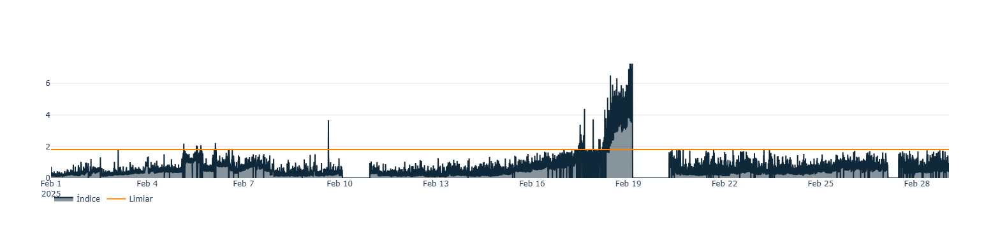

In [24]:
result = futurai.predict(df_test,eixoX_test)

fig_all_period, _ = utils.dev_graph_predict(result["phi"], result["timestamp"], futurai.phi_lim, " ", start_date, end_date, list_periods=None, plot_anomalies=False)
fig_all_period.show()

In [25]:
fig_all_period.write_html("output/Detecção-PCA_"+ process_name +".html")

## ANN-Based AutoEncoder

Tziolas, T.; Papageorgiou, K.; Theodosiou, T.; Papageorgiou, E.; Mastos, T.; Papadopoulos, A. Autoencoders for Anomaly Detection in an Industrial Multivariate Time Series Dataset. Eng. Proc. 2022, 18, 23. https://doi.org/10.3390/engproc2022018023

In [26]:
class ANN_Autoencoder(nn.Module):
    def __init__(self, seq_len=60, n_features=3):
        super(ANN_Autoencoder, self).__init__()
        
        self.seq_len = seq_len
        self.n_features = n_features
        
        # Encoder
        # "Input (128-64-32)-flatten-1024-latent space (128)"
        self.enc_layer1 = nn.Linear(n_features, 128)
        self.enc_layer2 = nn.Linear(128, 64)
        self.enc_layer3 = nn.Linear(64, 32)
        
        # Flatten
        self.flatten_dim = seq_len * 32
        
        self.enc_layer4 = nn.Linear(self.flatten_dim, 1024)
        self.latent_layer = nn.Linear(1024, 128) # Latent Space
        
        # Decoder
        # "(1024-64-32)-reshape (64-128)-output" 
        self.dec_layer1 = nn.Linear(128, 1024)
        self.dec_layer2 = nn.Linear(1024, self.flatten_dim)
        
        # Reshape
        self.dec_layer3 = nn.Linear(32, 64)
        self.dec_layer4 = nn.Linear(64, 128)
        self.output_layer = nn.Linear(128, n_features)
        
        self.relu = nn.ReLU()

    def forward(self, x):
        # x shape: [batch_size, 60, n_features]
        
        # Encoder Pass
        x = self.relu(self.enc_layer1(x))
        x = self.relu(self.enc_layer2(x))
        x = self.relu(self.enc_layer3(x)) # Output: [batch, 60, 32]
        
        # Flatten
        x = x.view(x.size(0), -1)         # Output: [batch, 1920]
        
        x = self.relu(self.enc_layer4(x))
        latent = self.relu(self.latent_layer(x)) # Output: [batch, 128]
        
        # Decoder Pass
        x = self.relu(self.dec_layer1(latent))
        x = self.relu(self.dec_layer2(x)) # Output: [batch, 1920]
        
        # Reshape (unflatten)
        x = x.view(x.size(0), self.seq_len, 32) # Output: [batch, 60, 32]
        
        x = self.relu(self.dec_layer3(x))
        x = self.relu(self.dec_layer4(x))
        
        reconstruction = self.output_layer(x) # Output: [batch, 60, n_features]
        
        return reconstruction

In [27]:
SEQ_LEN = 10
STRIDE = 1
BATCH_SIZE = 128 # Valor padrão de mercado (32 a 128)
LR = 1e-3
EPOCHS = 100
PATIENCE = 70    # se não melhorar em 70 épocas para o treino

scaler = MinMaxScaler()
df_train_scaled = scaler.fit_transform(df_train)

def reshape_data(data, seq_len, stride=1):
    """
    (N, features) -> (Num_Janelas, seq_len, features)
    Parâmetros:
      stride (int): passo das janelas 
                    Se stride=1 -> máxima sobreposição
                    Se stride=seq_len -> sem sobreposição
    """
    xs = []
    for i in range(0, len(data) - seq_len + 1, stride):
        x = data[i:(i + seq_len)]
        xs.append(x)
    return np.array(xs)

X_train_full = reshape_data(df_train_scaled, SEQ_LEN, STRIDE)
tensor_data = torch.tensor(X_train_full, dtype=torch.float32)

train_size = int(0.9 * len(tensor_data))

train_tensor = tensor_data[:train_size]
val_tensor = tensor_data[train_size:]

train_dataset = TensorDataset(train_tensor)
val_dataset = TensorDataset(val_tensor)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

model_ann = ANN_Autoencoder(seq_len=SEQ_LEN, n_features=df_train.shape[1])
criterion = nn.MSELoss() ## L1Loss || MSELoss
optimizer = optim.Adam(model_ann.parameters(), lr=LR)

best_val_loss = float('inf')
patience_counter = 0

history_loss = []
val_history_loss = []

for epoch in range(EPOCHS):
    epoch = epoch+1
    model_ann.train()
    train_loss = 0
    for inputs in train_loader:
        if isinstance(inputs, list): inputs = inputs[0]
        optimizer.zero_grad()
        reconstructions = model_ann(inputs)
        loss = criterion(reconstructions, inputs)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    
    avg_train_loss = train_loss / len(train_loader)
    history_loss.append(avg_train_loss)
    
    model_ann.eval()
    val_loss = 0
    with torch.no_grad():
        for inputs in val_loader:
            if isinstance(inputs, list): inputs = inputs[0]
            reconstructions = model_ann(inputs)
            loss = criterion(reconstructions, inputs)
            val_loss += loss.item()
            
    avg_val_loss = val_loss / len(val_loader)
    val_history_loss.append(avg_val_loss)
    
    # Log
    if epoch % 10 == 0 or epoch == EPOCHS or epoch == 1:
        print(f"Epoch [{epoch}/{EPOCHS}] | Train Loss: {avg_train_loss:.6f} | Val Loss: {avg_val_loss:.6f}")
    
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        patience_counter = 0
        # Salvar o melhor modelo
        torch.save(model_ann.state_dict(), 'best_model.pth')
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"Parada antecipada na época {epoch}. Melhor Val Loss: {best_val_loss:.6f}")
            # Recarregar o melhor modelo
            model_ann.load_state_dict(torch.load('best_model.pth'))
            break

Epoch [1/100] | Train Loss: 0.051900 | Val Loss: 0.057572
Epoch [10/100] | Train Loss: 0.005549 | Val Loss: 0.041875
Epoch [20/100] | Train Loss: 0.003902 | Val Loss: 0.040327
Epoch [30/100] | Train Loss: 0.002894 | Val Loss: 0.036985
Epoch [40/100] | Train Loss: 0.002457 | Val Loss: 0.035853
Epoch [50/100] | Train Loss: 0.002132 | Val Loss: 0.032001
Epoch [60/100] | Train Loss: 0.001967 | Val Loss: 0.036675
Epoch [70/100] | Train Loss: 0.001858 | Val Loss: 0.037211
Epoch [80/100] | Train Loss: 0.001793 | Val Loss: 0.036777
Epoch [90/100] | Train Loss: 0.001740 | Val Loss: 0.036222
Epoch [100/100] | Train Loss: 0.001682 | Val Loss: 0.036592


In [28]:
model_ann.eval()
all_mae_losses = []

with torch.no_grad():
    for batch in train_loader:
        inputs = batch[0]
        reconstructions = model_ann(inputs)
        # Calcula MAE por amostra -> Result shape: [batch_size]
        batch_loss = torch.mean(torch.abs(reconstructions - inputs), dim=[1, 2])
        all_mae_losses.extend(batch_loss.cpu().numpy())
        
train_mae_loss = np.array(all_mae_losses)
THRESHOLD = round(np.mean(train_mae_loss) + (20 * np.std(train_mae_loss)), 2)

print(f"Média do Erro no treino: {np.mean(train_mae_loss):.6f}")
print(f"Desvio Padrão no treino: {np.std(train_mae_loss):.6f}")
print(f"Anomaly Threshold: {THRESHOLD:.2f}")

Média do Erro no treino: 0.024280
Desvio Padrão no treino: 0.005206
Anomaly Threshold: 0.13


In [29]:
def predict(df_test, timestamps, modelo, scaler, threshold, batch_size=32):
    
    X_test_scaled = scaler.transform(df_test.values)

    seq_len = modelo.seq_len
    sequences = reshape_data(X_test_scaled, SEQ_LEN, STRIDE)
    
    if len(sequences) == 0:
        return pd.DataFrame()

    dataset = TensorDataset(torch.tensor(sequences, dtype=torch.float32))
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    all_losses = []
    modelo.eval()
    with torch.no_grad():
        for batch in loader:
            inputs = batch[0] # Se estiver usando GPU: .to(device)
            reconstruction = modelo(inputs)
            
            # MAE por janela (Batch, Seq, Features) -> Média sobre eixos 1 e 2
            batch_loss = torch.mean(torch.abs(reconstruction - inputs), dim=[1, 2])
            all_losses.extend(batch_loss.cpu().numpy())


    if hasattr(timestamps, 'values'):
        ts_values = timestamps.values
    else:
        ts_values = np.array(timestamps)

    valid_timestamps = ts_values[seq_len - 1 :: STRIDE]
    min_len = min(len(all_losses), len(valid_timestamps))
    df_resultado = pd.DataFrame({
        'timestamp': valid_timestamps[:min_len],
        'loss': all_losses[:min_len]
    })
    df_resultado.set_index('timestamp', inplace=True)
    df_resultado = df_resultado.asfreq('1min')
    df_resultado['loss'] = df_resultado['loss'].fillna(0)
    
    return df_resultado

df_predict_ann = predict(
    df_test, 
    eixoX_test, 
    model_ann,
    scaler, 
    THRESHOLD, 
    batch_size=BATCH_SIZE
)

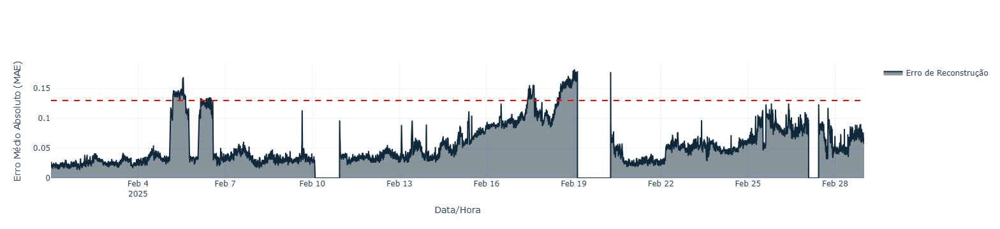

In [30]:
def plot_predict(df_predict, threshold):
    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=df_predict.index,
        y=df_predict['loss'],
        mode='lines',
        name='Erro de Reconstrução',
        fill="tozeroy", 
        line=dict(color="#0F293A"),
        connectgaps=False
    ))
    
    fig.add_hline(
        y=threshold, 
        name='Limiar',
        line_dash="dash", 
        line_color="red", 
        line_width=2
    )
    
    fig.update_layout(
        xaxis_title='Data/Hora',
        yaxis_title='Erro Médio Absoluto (MAE)',
        template='plotly_white',
        hovermode="x unified",
        showlegend=True
    )

    return fig

fig = plot_predict(df_predict_ann, THRESHOLD)
fig.show()

In [31]:
fig.write_html("output/Detecção-AE_"+ process_name +".html")

## LSTM-Based AutoEncoder

Tziolas, T.; Papageorgiou, K.; Theodosiou, T.; Papageorgiou, E.; Mastos, T.; Papadopoulos, A. Autoencoders for Anomaly Detection in an Industrial Multivariate Time Series Dataset. Eng. Proc. 2022, 18, 23. https://doi.org/10.3390/engproc2022018023

In [39]:
class LSTM_Autoencoder(nn.Module):
    def __init__(self, seq_len=60, n_features=3, hidden_dim=128):
        super(LSTM_Autoencoder, self).__init__()
        
        self.seq_len = seq_len
        self.n_features = n_features
        self.hidden_dim = hidden_dim
        
        # --- Encoder ---
        # Input: [batch, 60, 3] -> Output: [batch, 60, 128]
        self.encoder_l1 = nn.LSTM(
            input_size=n_features, 
            hidden_size=hidden_dim, 
            batch_first=True
        )
        
        # Input: [batch, 60, 128] -> Output (Last Hidden): [batch, 128]
        self.encoder_l2 = nn.LSTM(
            input_size=hidden_dim, 
            hidden_size=hidden_dim, 
            batch_first=True
        )
        
        # --- Decoder ---
        # Input: [batch, 60, 128] -> Output: [batch, 60, 128]
        self.decoder_l1 = nn.LSTM(
            input_size=hidden_dim, 
            hidden_size=hidden_dim, 
            batch_first=True
        )
        
        # Camada 2 (Saída): Reconstrói as features originais
        # Input: [batch, 60, 128] -> Output: [batch, 60, 3]
        self.decoder_l2 = nn.LSTM(
            input_size=hidden_dim, 
            hidden_size=n_features, 
            batch_first=True
        )

    def forward(self, x):
        # x shape: [batch, 60, 3]
        
        # Encoder Pass
        # save enc_out1 for Skip Connection
        enc_out1, _ = self.encoder_l1(x) # shape: [batch, 60, 128]
        
        # Segunda camada LSTM apenas o último estado oculto
        _, (hidden, _) = self.encoder_l2(enc_out1)
        latent = hidden[-1] # shape: [batch, 128]
        
        # Repeat Vector
        # Repete o vetor latente 60 vezes para corresponder a sequência temporal
        # [batch, 128] -> [batch, 60, 128]
        repeat_vect = latent.unsqueeze(1).repeat(1, self.seq_len, 1)
        
        # Skip Connection
        decoder_input = enc_out1 + repeat_vect 
        
        # Decoder Pass
        dec_out1, _ = self.decoder_l1(decoder_input)
        
        # Camada final de reconstrução
        reconstruction, _ = self.decoder_l2(dec_out1)
        
        return reconstruction

In [40]:
SEQ_LEN = 10
STRIDE = 1
BATCH_SIZE = 128 # Valor padrão de mercado (32 a 128)
LR = 1e-3
EPOCHS = 100
PATIENCE = 70    # se não melhorar em 70 épocas para o treino

scaler = MinMaxScaler(feature_range=(-1, 1))
df_train_scaled = scaler.fit_transform(df_train)

def reshape_data(data, seq_len, stride=1):
    """
    (N, features) -> (Num_Janelas, seq_len, features)
    Parâmetros:
      stride (int): passo das janelas 
                    Se stride=1 -> máxima sobreposição
                    Se stride=seq_len -> sem sobreposição
    """
    xs = []
    for i in range(0, len(data) - seq_len + 1, stride):
        x = data[i:(i + seq_len)]
        xs.append(x)
    return np.array(xs)

X_train_full = reshape_data(df_train_scaled, SEQ_LEN, STRIDE)
tensor_data = torch.tensor(X_train_full, dtype=torch.float32)

train_size = int(0.9 * len(tensor_data))

train_tensor = tensor_data[:train_size]
val_tensor = tensor_data[train_size:]

train_dataset = TensorDataset(train_tensor)
val_dataset = TensorDataset(val_tensor)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

model_lstm = LSTM_Autoencoder(seq_len=SEQ_LEN, n_features=df_train.shape[1], hidden_dim=128)
criterion = nn.MSELoss() ## L1Loss || MSELoss
optimizer = optim.Adam(model_lstm.parameters(), lr=LR)

best_val_loss = float('inf')
patience_counter = 0

history_loss = []
val_history_loss = []

for epoch in range(EPOCHS):
    epoch = epoch+1
    model_lstm.train()
    train_loss = 0
    for inputs in train_loader:
        if isinstance(inputs, list): inputs = inputs[0]
        optimizer.zero_grad()
        reconstructions = model_lstm(inputs)
        loss = criterion(reconstructions, inputs)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    
    avg_train_loss = train_loss / len(train_loader)
    history_loss.append(avg_train_loss)
    
    model_lstm.eval()
    val_loss = 0
    with torch.no_grad():
        for inputs in val_loader:
            if isinstance(inputs, list): inputs = inputs[0]
            reconstructions = model_lstm(inputs)
            loss = criterion(reconstructions, inputs)
            val_loss += loss.item()
            
    avg_val_loss = val_loss / len(val_loader)
    val_history_loss.append(avg_val_loss)
    
    # Log
    if epoch % 10 == 0 or epoch == EPOCHS or epoch==1:
        print(f"Epoch [{epoch}/{EPOCHS}] | Train Loss: {avg_train_loss:.6f} | Val Loss: {avg_val_loss:.6f}")
    
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        patience_counter = 0
        # Salvar o melhor modelo
        torch.save(model_lstm.state_dict(), 'best_model.pth')
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"Parada antecipada na época {epoch}. Melhor Val Loss: {best_val_loss:.6f}")
            # Recarregar o melhor modelo
            model_lstm.load_state_dict(torch.load('best_model.pth'))
            break

Epoch [1/100] | Train Loss: 0.105237 | Val Loss: 0.252724
Epoch [10/100] | Train Loss: 0.013628 | Val Loss: 0.136609
Epoch [20/100] | Train Loss: 0.008501 | Val Loss: 0.120045
Epoch [30/100] | Train Loss: 0.007155 | Val Loss: 0.113823
Epoch [40/100] | Train Loss: 0.005831 | Val Loss: 0.104919
Epoch [50/100] | Train Loss: 0.005405 | Val Loss: 0.099413
Epoch [60/100] | Train Loss: 0.005267 | Val Loss: 0.095119
Epoch [70/100] | Train Loss: 0.005166 | Val Loss: 0.092644
Epoch [80/100] | Train Loss: 0.005096 | Val Loss: 0.092444
Epoch [90/100] | Train Loss: 0.005037 | Val Loss: 0.088483
Epoch [100/100] | Train Loss: 0.004979 | Val Loss: 0.080148


In [41]:
model_lstm.eval()
all_mae_losses = []

with torch.no_grad():
    for batch in train_loader:
        inputs = batch[0]
        reconstructions = model_lstm(inputs)
        # Calcula MAE por amostra -> Result shape: [batch_size]
        batch_loss = torch.mean(torch.abs(reconstructions - inputs), dim=[1, 2])
        all_mae_losses.extend(batch_loss.cpu().numpy())
        
train_mae_loss = np.array(all_mae_losses)
THRESHOLD = round(np.mean(train_mae_loss) + (5 * np.std(train_mae_loss)), 2)

print(f"Média do Erro: {np.mean(train_mae_loss):.6f}")
print(f"Desvio Padrão: {np.std(train_mae_loss):.6f}")
print(f"Anomaly Threshold: {THRESHOLD:.2f}")

Média do Erro: 0.021223
Desvio Padrão: 0.016822
Anomaly Threshold: 0.11


In [42]:
def predict(df_test, timestamps, modelo, scaler, threshold, batch_size=32):
    
    X_test_scaled = scaler.transform(df_test.values)

    seq_len = modelo.seq_len
    sequences = reshape_data(X_test_scaled, SEQ_LEN, STRIDE)
    
    if len(sequences) == 0:
        return pd.DataFrame()

    dataset = TensorDataset(torch.tensor(sequences, dtype=torch.float32))
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    all_losses = []
    modelo.eval()
    with torch.no_grad():
        for batch in loader:
            inputs = batch[0] # Se estiver usando GPU: .to(device)
            reconstruction = modelo(inputs)
            
            # MAE por janela (Batch, Seq, Features) -> Média sobre eixos 1 e 2
            batch_loss = torch.mean(torch.abs(reconstruction - inputs), dim=[1, 2])
            all_losses.extend(batch_loss.cpu().numpy())


    if hasattr(timestamps, 'values'):
        ts_values = timestamps.values
    else:
        ts_values = np.array(timestamps)

    valid_timestamps = ts_values[seq_len - 1 :: STRIDE]
    min_len = min(len(all_losses), len(valid_timestamps))
    df_resultado = pd.DataFrame({
        'timestamp': valid_timestamps[:min_len],
        'loss': all_losses[:min_len]
    })
    df_resultado.set_index('timestamp', inplace=True)
    df_resultado = df_resultado.asfreq('1min')
    df_resultado['loss'] = df_resultado['loss'].fillna(0)
    
    return df_resultado

df_predict_lstm = predict(
    df_test, 
    eixoX_test, 
    model_lstm,
    scaler, 
    THRESHOLD, 
    batch_size=BATCH_SIZE
)

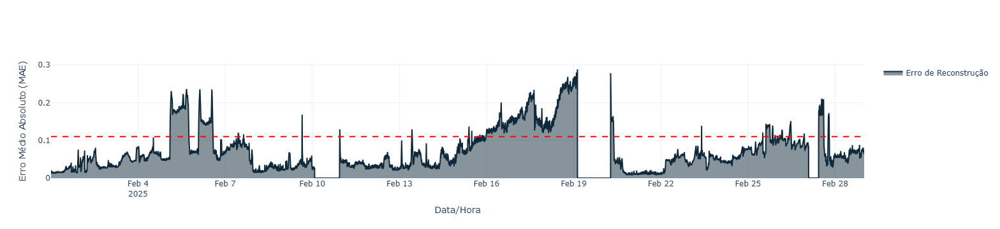

In [43]:
def plot_predict(df_predict, threshold):
    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=df_predict.index,
        y=df_predict['loss'],
        mode='lines',
        name='Erro de Reconstrução',
        fill="tozeroy", 
        line=dict(color="#0F293A"),
        connectgaps=False
    ))
    
    fig.add_hline(
        y=threshold, 
        name='Limiar',
        line_dash="dash", 
        line_color="red", 
        line_width=2
    )
    
    fig.update_layout(
        xaxis_title='Data/Hora',
        yaxis_title='Erro Médio Absoluto (MAE)',
        template='plotly_white',
        hovermode="x unified",
        showlegend=True
    )

    return fig

fig = plot_predict(df_predict_lstm, THRESHOLD)
fig.show()

In [44]:
fig.write_html("output/Detecção-LSTMAE_"+ process_name +".html")

## CNN-Based AutoEncoder

Tziolas, T.; Papageorgiou, K.; Theodosiou, T.; Papageorgiou, E.; Mastos, T.; Papadopoulos, A. Autoencoders for Anomaly Detection in an Industrial Multivariate Time Series Dataset. Eng. Proc. 2022, 18, 23. https://doi.org/10.3390/engproc2022018023

In [45]:
class CNN_Autoencoder(nn.Module):
    def __init__(self, seq_len=60, n_features=3):
        super(CNN_Autoencoder, self).__init__()
        self.seq_len = seq_len
        self.n_features = n_features

        # --- ENCODER ---
        # Layer 1: Conv1D 64, kernel 15, stride 3
        self.enc_conv1 = nn.Conv1d(in_channels=n_features, out_channels=64, kernel_size=15, stride=3, padding=7)
        
        # Layer 2: Conv1D 32, kernel 9, stride 2
        self.enc_conv2 = nn.Conv1d(64, 32, kernel_size=9, stride=2, padding=4)
        
        # Layer 3: Conv1D 16, kernel 7, stride 2
        self.enc_conv3 = nn.Conv1d(32, 16, kernel_size=7, stride=2, padding=3)
        
        # Layer 4: Conv1D 8, kernel 3, stride 1
        self.enc_conv4 = nn.Conv1d(16, 8, kernel_size=3, stride=1, padding=1)
        
        # Max Pooling: Size 2, Stride 2
        self.max_pool = nn.MaxPool1d(kernel_size=2, stride=2)

        # --- DECODER ---
        # Utiliza Transpose Convolutions para Up-sampling 
        
        # Layer 1 Decoder: TranspConv 16, kernel 3, stride 2
        self.dec_trans1 = nn.ConvTranspose1d(8, 16, kernel_size=3, stride=2, padding=1, output_padding=1)
        
        # Layer 2 Decoder: TranspConv 32, kernel 7, stride 2
        self.dec_trans2 = nn.ConvTranspose1d(16, 32, kernel_size=7, stride=2, padding=3, output_padding=1)
        
        # Layer 3 Decoder: TranspConv 64, kernel 9, stride 2
        self.dec_trans3 = nn.ConvTranspose1d(32, 64, kernel_size=9, stride=2, padding=4, output_padding=1)
        
        # Layer 4 Decoder: TranspConv 64, kernel 15, stride 3
        self.dec_trans4 = nn.ConvTranspose1d(64, 64, kernel_size=15, stride=3, padding=7, output_padding=1)
        
        # Camada Final: Linear/Conv1d com kernel 1 para voltar as features originais
        self.dec_final = nn.Conv1d(64, n_features, kernel_size=1, stride=1)
        
        self.relu = nn.ReLU()

    def forward(self, x):
        # x input shape: [batch, seq_len=60, features=3]
        
        # 1. Transpor para formato CNN: [batch, 3, 60]
        x = x.permute(0, 2, 1)
        
        # --- Encoder Pass ---
        x = self.relu(self.enc_conv1(x))
        x = self.relu(self.enc_conv2(x))
        x = self.relu(self.enc_conv3(x))
        x = self.relu(self.enc_conv4(x))
        x = self.max_pool(x)
        
        # --- Decoder Pass ---
        x = self.relu(self.dec_trans1(x))
        x = self.relu(self.dec_trans2(x))
        x = self.relu(self.dec_trans3(x))
        x = self.relu(self.dec_trans4(x))
        
        # Output layer (sem ativação se os dados forem normalizados, ou Sigmoid se for 0-1)
        x = self.dec_final(x)
        
        # Ajuste Fino de Tamanho: 
        # Como convoluções com stride em sequências pequenas (60) podem perder pixels exatos,
        # forçamos a interpolação para garantir que a saída seja exatamente 60.
        if x.shape[2] != self.seq_len:
            x = F.interpolate(x, size=self.seq_len, mode='linear', align_corners=False)
        
        # 2. Transpor de volta para formato original: [batch, 60, 3]
        x = x.permute(0, 2, 1)
        
        return x

In [46]:
SEQ_LEN = 15
STRIDE = 1
BATCH_SIZE = 128 # Valor padrão de mercado (32 a 128)
LR = 1e-3
EPOCHS = 100
PATIENCE = 70    # se não melhorar em 70 épocas para o treino

scaler = MinMaxScaler()
df_train_scaled = scaler.fit_transform(df_train)

def reshape_data(data, seq_len, stride=1):
    """
    (N, features) -> (Num_Janelas, seq_len, features)
    Parâmetros:
      stride (int): passo das janelas 
                    Se stride=1 -> máxima sobreposição
                    Se stride=seq_len -> sem sobreposição
    """
    xs = []
    for i in range(0, len(data) - seq_len + 1, stride):
        x = data[i:(i + seq_len)]
        xs.append(x)
    return np.array(xs)

X_train_full = reshape_data(df_train_scaled, SEQ_LEN, STRIDE)
tensor_data = torch.tensor(X_train_full, dtype=torch.float32)

train_size = int(0.9 * len(tensor_data))

train_tensor = tensor_data[:train_size]
val_tensor = tensor_data[train_size:]

train_dataset = TensorDataset(train_tensor)
val_dataset = TensorDataset(val_tensor)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

model_cnn = CNN_Autoencoder(seq_len=SEQ_LEN, n_features=df_train.shape[1])
criterion = nn.MSELoss() ## L1Loss || MSELoss
optimizer = optim.Adam(model_cnn.parameters(), lr=LR)

best_val_loss = float('inf')
patience_counter = 0

history_loss = []
val_history_loss = []

for epoch in range(EPOCHS):
    epoch = epoch+1
    model_cnn.train()
    train_loss = 0
    for inputs in train_loader:
        if isinstance(inputs, list): inputs = inputs[0]
        optimizer.zero_grad()
        reconstructions = model_cnn(inputs)
        loss = criterion(reconstructions, inputs)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    
    avg_train_loss = train_loss / len(train_loader)
    history_loss.append(avg_train_loss)
    
    model_cnn.eval()
    val_loss = 0
    with torch.no_grad():
        for inputs in val_loader:
            if isinstance(inputs, list): inputs = inputs[0]
            reconstructions = model_cnn(inputs)
            loss = criterion(reconstructions, inputs)
            val_loss += loss.item()
            
    avg_val_loss = val_loss / len(val_loader)
    val_history_loss.append(avg_val_loss)
    
    # Log
    if epoch % 10 == 0 or epoch == EPOCHS or epoch == 1:
        print(f"Epoch [{epoch}/{EPOCHS}] | Train Loss: {avg_train_loss:.6f} | Val Loss: {avg_val_loss:.6f}")
    
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        patience_counter = 0
        # Salvar o melhor modelo
        torch.save(model_cnn.state_dict(), 'best_model.pth')
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"Parada antecipada na época {epoch}. Melhor Val Loss: {best_val_loss:.6f}")
            # Recarregar o melhor modelo
            model_cnn.load_state_dict(torch.load('best_model.pth'))
            break

Epoch [1/100] | Train Loss: 0.108348 | Val Loss: 0.064972
Epoch [10/100] | Train Loss: 0.007815 | Val Loss: 0.049131
Epoch [20/100] | Train Loss: 0.005520 | Val Loss: 0.048011
Epoch [30/100] | Train Loss: 0.004087 | Val Loss: 0.045427
Epoch [40/100] | Train Loss: 0.003404 | Val Loss: 0.043542
Epoch [50/100] | Train Loss: 0.003036 | Val Loss: 0.045021
Epoch [60/100] | Train Loss: 0.002877 | Val Loss: 0.041535
Epoch [70/100] | Train Loss: 0.002690 | Val Loss: 0.040863
Epoch [80/100] | Train Loss: 0.002550 | Val Loss: 0.042352
Epoch [90/100] | Train Loss: 0.002415 | Val Loss: 0.042839
Epoch [100/100] | Train Loss: 0.002310 | Val Loss: 0.042895


In [56]:
model_cnn.eval()
all_mae_losses = []

with torch.no_grad():
    for batch in train_loader:
        inputs = batch[0]
        
        reconstructions = model_cnn(inputs)
        
        # Calcula MAE por amostra -> Result shape: [batch_size]
        batch_loss = torch.mean(torch.abs(reconstructions - inputs), dim=[1, 2])
        
        all_mae_losses.extend(batch_loss.cpu().numpy())
        
train_mae_loss = np.array(all_mae_losses)
THRESHOLD = round(np.mean(train_mae_loss) + (5 * np.std(train_mae_loss)), 2)

print(f"Média do Erro: {np.mean(train_mae_loss):.6f}")
print(f"Desvio Padrão: {np.std(train_mae_loss):.6f}")
print(f"Anomaly Threshold: {THRESHOLD:.2f}")

Média do Erro: 0.028901
Desvio Padrão: 0.010763
Anomaly Threshold: 0.08


In [57]:
def predict(df_test, timestamps, modelo, scaler, threshold, batch_size=32):
    
    X_test_scaled = scaler.transform(df_test.values)

    seq_len = modelo.seq_len
    sequences = reshape_data(X_test_scaled, SEQ_LEN, STRIDE)
    
    if len(sequences) == 0:
        return pd.DataFrame()

    dataset = TensorDataset(torch.tensor(sequences, dtype=torch.float32))
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    all_losses = []
    modelo.eval()
    with torch.no_grad():
        for batch in loader:
            inputs = batch[0] # Se estiver usando GPU: .to(device)
            reconstruction = modelo(inputs)
            
            # MAE por janela (Batch, Seq, Features) -> Média sobre eixos 1 e 2
            batch_loss = torch.mean(torch.abs(reconstruction - inputs), dim=[1, 2])
            all_losses.extend(batch_loss.cpu().numpy())


    if hasattr(timestamps, 'values'):
        ts_values = timestamps.values
    else:
        ts_values = np.array(timestamps)

    valid_timestamps = ts_values[seq_len - 1 :: STRIDE]
    min_len = min(len(all_losses), len(valid_timestamps))
    df_resultado = pd.DataFrame({
        'timestamp': valid_timestamps[:min_len],
        'loss': all_losses[:min_len]
    })
    df_resultado.set_index('timestamp', inplace=True)
    df_resultado = df_resultado.asfreq('1min')
    df_resultado['loss'] = df_resultado['loss'].fillna(0)
    
    return df_resultado

df_predict_cnn = predict(
    df_test, 
    eixoX_test, 
    model_cnn,
    scaler, 
    THRESHOLD, 
    batch_size=BATCH_SIZE
)

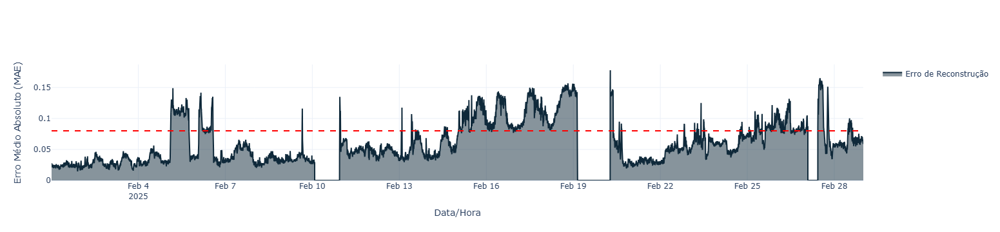

In [58]:
def plot_predict(df_predict, threshold):
    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=df_predict.index,
        y=df_predict['loss'],
        mode='lines',
        name='Erro de Reconstrução',
        fill="tozeroy", 
        line=dict(color="#0F293A"),
        connectgaps=False
    ))
    
    fig.add_hline(
        y=threshold, 
        name='Limiar',
        line_dash="dash", 
        line_color="red", 
        line_width=2
    )
    
    fig.update_layout(
        xaxis_title='Data/Hora',
        yaxis_title='Erro Médio Absoluto (MAE)',
        template='plotly_white',
        hovermode="x unified",
        showlegend=True
    )

    return fig

fig = plot_predict(df_predict_cnn, THRESHOLD)
fig.show()

In [59]:
fig.write_html("output/Detecção-CNNAE_"+ process_name +".html")

## USAD

Audibert, J., Michiardi, P., Guyard, F., Marti, S., Zuluaga, M. A. (2020).
USAD : UnSupervised Anomaly Detection on multivariate time series.
Proceedings of the 26th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining, August 23-27, 2020

In [60]:
def get_default_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    else:
        return torch.device('cpu')
device = get_default_device()

class Encoder(nn.Module):
    def __init__(self, in_size, latent_size):
        super().__init__()
        # Arquitetura conforme Apêndice A.4.1
        self.linear1 = nn.Linear(in_size, int(in_size/2))
        self.linear2 = nn.Linear(int(in_size/2), int(in_size/4))
        self.linear3 = nn.Linear(int(in_size/4), latent_size)
        self.relu = nn.ReLU(True)
        
    def forward(self, w):
        out = self.linear1(w)
        out = self.relu(out)
        out = self.linear2(out)
        out = self.relu(out)
        out = self.linear3(out)
        z = self.relu(out)
        return z
    
class Decoder(nn.Module):
    def __init__(self, latent_size, out_size):
        super().__init__()
        # Arquitetura conforme Apêndice A.4.2 [cite: 512-515]
        self.linear1 = nn.Linear(latent_size, int(out_size/4))
        self.linear2 = nn.Linear(int(out_size/4), int(out_size/2))
        self.linear3 = nn.Linear(int(out_size/2), out_size)
        self.relu = nn.ReLU(True)
        self.sigmoid = nn.Sigmoid()
        
    def forward(self, z):
        out = self.linear1(z)
        out = self.relu(out)
        out = self.linear2(out)
        out = self.relu(out)
        out = self.linear3(out)
        w = self.sigmoid(out)
        return w
    
class UsadModel(nn.Module):
    def __init__(self, w_size, z_size):
        super().__init__()
        self.encoder = Encoder(w_size, z_size)
        self.decoder1 = Decoder(z_size, w_size)
        self.decoder2 = Decoder(z_size, w_size)
  
    def training_step(self, batch, n):
        # Implementação das Equações (7) e (8)
        z = self.encoder(batch)
        w1 = self.decoder1(z)
        w2 = self.decoder2(z)
        w3 = self.decoder2(self.encoder(w1))
        
        # Loss 1: Treina AE1 para reconstruir e enganar AE2
        loss1 = 1/n * torch.mean((batch - w1)**2) + (1 - 1/n) * torch.mean((batch - w3)**2)
        
        # Loss 2: Treina AE2 para distinguir real de reconstruído
        loss2 = 1/n * torch.mean((batch - w2)**2) - (1 - 1/n) * torch.mean((batch - w3)**2)
        
        return loss1, loss2

    def forward(self, batch):
        # Usado para inferência simples (apenas reconstrução do AE1 e AE2)
        z = self.encoder(batch)
        w1 = self.decoder1(z)
        w2 = self.decoder2(self.encoder(w1))
        return w1, w2

In [61]:
SEQ_LEN = 10
STRIDE = 1
BATCH_SIZE = 128
LR = 1e-3
EPOCHS = 1 # USAD converge rápido, mais epócas o modelo apresenta overfiting
Z_SIZE = 64 # Dimensão latente
ALPHA = 0.5
BETA = 0.5

scaler = MinMaxScaler()
df_train_scaled = scaler.fit_transform(df_train)

def reshape_data(data, seq_len, stride=1):
    xs = []
    for i in range(0, len(data) - seq_len + 1, stride):
        x = data[i:(i + seq_len)]
        xs.append(x)
    return np.array(xs)

X_train_full = reshape_data(df_train_scaled, SEQ_LEN, STRIDE)
tensor_data = torch.tensor(X_train_full, dtype=torch.float32)

# Divisão Treino/Validação
train_size = int(0.9 * len(tensor_data))
train_tensor = tensor_data[:train_size]
val_tensor = tensor_data[train_size:]

train_loader = DataLoader(TensorDataset(train_tensor), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(val_tensor), batch_size=BATCH_SIZE, shuffle=False)

# Inicialização do Modelo
W_SIZE = SEQ_LEN * df_train.shape[1] # Tamanho da janela achatada
model_usad = UsadModel(W_SIZE, Z_SIZE)
model_usad = model_usad.to(device)

# Otimizadores (Separados para AE1 e AE2 conforme arquitetura adversarial)
optimizer1 = torch.optim.Adam(list(model_usad.encoder.parameters()) + list(model_usad.decoder1.parameters()), lr=LR)
optimizer2 = torch.optim.Adam(list(model_usad.encoder.parameters()) + list(model_usad.decoder2.parameters()), lr=LR)

history = []
for epoch in range(EPOCHS):
    epoch=epoch+1
    model_usad.train()
    epoch_loss1 = 0
    epoch_loss2 = 0
    
    for batch in train_loader:
        inputs = batch[0].to(device)
        # Flatten: (Batch, Seq, Feat) -> (Batch, Seq*Feat)
        inputs = inputs.view(inputs.size(0), -1)
        
        # == Treino AE1 ==
        loss1, _ = model_usad.training_step(inputs, epoch + 1)
        optimizer1.zero_grad()
        loss1.backward()
        optimizer1.step()
        
        # == Treino AE2 ==
        _, loss2 = model_usad.training_step(inputs, epoch + 1)
        optimizer2.zero_grad()
        loss2.backward()
        optimizer2.step()
        
        epoch_loss1 += loss1.item()
        epoch_loss2 += loss2.item()
        
    # Validação (Fora do loop de batches para performance)
    model_usad.eval()
    val_loss1 = 0
    val_loss2 = 0
    with torch.no_grad():
        for batch in val_loader:
            inputs = batch[0].to(device)
            inputs = inputs.view(inputs.size(0), -1)
            l1, l2 = model_usad.training_step(inputs, epoch + 1)
            val_loss1 += l1.item()
            val_loss2 += l2.item()
            
    print(f"Epoch [{epoch}/{EPOCHS}] | Train Loss1: {epoch_loss1/len(train_loader):.4f} | Val Loss1: {val_loss1/len(val_loader):.4f}")

Epoch [1/1] | Train Loss1: 0.0636 | Val Loss1: 0.0901


In [71]:
def get_usad_scores(model, loader, alpha, beta):
    model.eval()
    scores = []
    with torch.no_grad():
        for batch in loader:
            inputs = batch[0].to(device)
            inputs = inputs.view(inputs.size(0), -1)
            
            w1 = model.decoder1(model.encoder(inputs))
            w2 = model.decoder2(model.encoder(w1))
            
            # Equação 9: Score = Alpha * Diff1 + Beta * Diff2
            diff1 = torch.mean((inputs - w1)**2, axis=1)
            diff2 = torch.mean((inputs - w2)**2, axis=1)
            score = alpha * diff1 + beta * diff2
            
            scores.extend(score.cpu().numpy())
    return np.array(scores)

# Calculando scores no treino para definir o Threshold
train_scores = get_usad_scores(model_usad, train_loader, ALPHA, BETA)
THRESHOLD = np.mean(train_scores) + (1.5 * np.std(train_scores))

print(f"Média Score Treino: {np.mean(train_scores):.6f}")
print(f"Threshold Definido: {THRESHOLD:.4f}")

Média Score Treino: 0.034719
Threshold Definido: 0.0613


In [72]:
def predict_usad(df_test, timestamps, model, scaler):
    X_test_scaled = scaler.transform(df_test.values)
    sequences = reshape_data(X_test_scaled, SEQ_LEN, STRIDE)
    
    if len(sequences) == 0:
        return pd.DataFrame()

    dataset = TensorDataset(torch.tensor(sequences, dtype=torch.float32))
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    scores = get_usad_scores(model, loader, ALPHA, BETA)
    
    if isinstance(timestamps, pd.Series) or isinstance(timestamps, pd.DataFrame):
        timestamps = timestamps.values
        
    valid_timestamps = timestamps[SEQ_LEN-1 :: STRIDE]
    
    min_len = min(len(scores), len(valid_timestamps))
    scores = scores[:min_len]
    valid_timestamps = valid_timestamps[:min_len]
    
    df_predict = pd.DataFrame({
        'timestamp': valid_timestamps,
        'anomaly_score': scores
    })
    df_predict.set_index('timestamp', inplace=True)
    df_predict = df_predict.asfreq('1min')
    df_predict['anomaly_score'] = df_predict['anomaly_score'].fillna(0)
    
    return df_predict

df_predict_usad = predict_usad(
    df_test=df_test, 
    timestamps=eixoX_test, 
    model=model_usad, 
    scaler=scaler
)

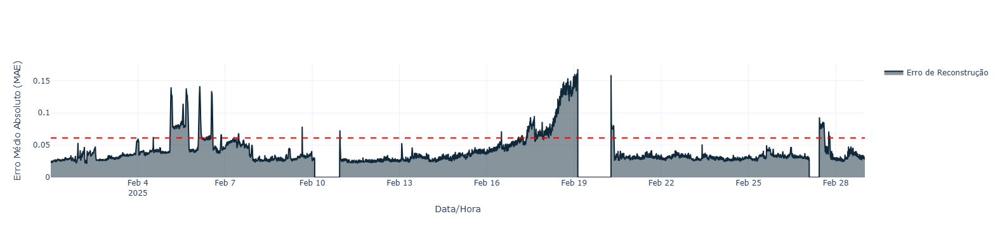

In [73]:
def plot_predict(df_predict, threshold):
    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=df_predict.index,
        y=df_predict['anomaly_score'],
        mode='lines',
        name='Erro de Reconstrução',
        fill="tozeroy", 
        line=dict(color="#0F293A"),
        connectgaps=False
    ))
    
    fig.add_hline(
        y=threshold, 
        name='Limiar',
        line_dash="dash", 
        line_color="red", 
        line_width=2
    )
    
    fig.update_layout(
        xaxis_title='Data/Hora',
        yaxis_title='Erro Médio Absoluto (MAE)',
        template='plotly_white',
        hovermode="x unified",
        showlegend=True
    )

    return fig

fig = plot_predict(df_predict_usad, THRESHOLD)
fig.show()

In [74]:
fig.write_html("output/Detecção-USAD_"+ process_name +".html")

## OmniAnomaly

Ya Su, Youjian Zhao, Chenhao Niu, Rong Liu, Wei Sun, and Dan Pei. 2019. Robust Anomaly Detection for Multivariate Time Series through Stochastic Recurrent Neural Network. In Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining (KDD '19). Association for Computing Machinery, New York, NY, USA, 2828–2837. https://doi.org/10.1145/3292500.3330672

In [75]:
class PlanarFlow(nn.Module):
    """
    Planar Normalizing Flow.
    z_f = z + u * h(w^T * z + b)
    """
    def __init__(self, dim):
        super(PlanarFlow, self).__init__()
        self.w = nn.Parameter(torch.randn(1, dim))
        self.b = nn.Parameter(torch.randn(1))
        self.u = nn.Parameter(torch.randn(1, dim))

    def h(self, x):
        return torch.tanh(x)

    def h_prime(self, x):
        return 1 - torch.tanh(x) ** 2

    def forward(self, z):
        # z: [batch, seq_len, dim] or [batch, dim]
        # We want to apply this to the last dimension.
        
        # Safe constraint for u to ensure invertibility
        # u^T * w > -1
        w_dot_u = torch.sum(self.w * self.u)
        m_w_dot_u = -1 + torch.log(1 + torch.exp(w_dot_u))
        u_hat = self.u + (m_w_dot_u - w_dot_u) * self.w / (torch.sum(self.w ** 2) + 1e-7)
        
        # Linear projection
        # Expand w, b, u for broadcasting
        # w: [1, dim]
        # z: [..., dim]
        
        # w^T * z + b
        # shape: [..., 1]
        lin = F.linear(z, self.w, self.b) 
        
        # f(z) = z + u * h(lin)
        f_z = z + u_hat * self.h(lin)
        
        # Log determinant of Jacobian
        # psi = h'(lin) * w
        psi = self.h_prime(lin) * self.w # [..., dim]
        
        # det = |1 + u^T * psi|
        det = 1 + torch.sum(u_hat * psi, dim=-1, keepdim=True)
        log_det = torch.log(torch.abs(det) + 1e-7)
        
        return f_z, log_det

class FlowSequential(nn.Sequential):
    def forward(self, z):
        log_det_sum = 0
        for modules in self:
            z, log_det = modules(z)
            log_det_sum = log_det_sum + log_det
        return z, log_det_sum

class Encoder(nn.Module):
    def __init__(self, x_dim, z_dim, hidden_dim, rnn_num_layers=1):
        super(Encoder, self).__init__()
        self.z_dim = z_dim
        self.hidden_dim = hidden_dim
        
        # h_for_q_z: RNN over x
        self.gru = nn.GRU(x_dim, hidden_dim, rnn_num_layers, batch_first=True)
        
        # Processing RNN output
        self.post_rnn = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.1),
            nn.Linear(hidden_dim, hidden_dim), # To match hidden_dense=2 logic roughly 
            nn.LeakyReLU(0.1)
        )
        
        # q_z_given_x parameters: predicts mu and sigma from (rnn_out, z_prev)
        self.z_mean = nn.Linear(hidden_dim + z_dim, z_dim)
        self.z_std = nn.Linear(hidden_dim + z_dim, z_dim)
        
    def forward(self, x, n_samples=1):
        # x: [batch, seq_len, x_dim]
        batch_size, seq_len, _ = x.size()
        
        # Pass x through RNN
        # h_seq: [batch, seq_len, hidden_dim]
        h_seq, _ = self.gru(x)
        
        # Post-process hidden states
        h_seq = self.post_rnn(h_seq)
        
        # Autoregressive generation of z
        # We need to sample z_t sequentially
        
        z_samples = []
        mu_list = []
        std_list = []
        
        # Initial z_prev (zeros or learned parameter)
        z_prev = torch.zeros(batch_size, self.z_dim).to(x.device)
        
        for t in range(seq_len):
            # context from x at time t
            h_t = h_seq[:, t, :] # [batch, hidden_dim]
            
            # Input to dist networks
            inp = torch.cat([h_t, z_prev], dim=1) # [batch, hidden_dim + z_dim]
            
            mu = self.z_mean(inp)
            std = F.softplus(self.z_std(inp)) + 1e-4
            
            # Sample z_t
            # epsilon ~ N(0, 1)
            eps = torch.randn_like(mu)
            z_t = mu + std * eps
            
            z_samples.append(z_t)
            mu_list.append(mu)
            std_list.append(std)
            
            z_prev = z_t
            
        # Stack
        z_out = torch.stack(z_samples, dim=1) # [batch, seq_len, z_dim]
        mu_out = torch.stack(mu_list, dim=1)
        std_out = torch.stack(std_list, dim=1)
        
        return z_out, mu_out, std_out

class Decoder(nn.Module):
    def __init__(self, x_dim, z_dim, hidden_dim, rnn_num_layers=1):
        super(Decoder, self).__init__()
        
        # h_for_p_x: RNN over z
        self.gru = nn.GRU(z_dim, hidden_dim, rnn_num_layers, batch_first=True)
        
        self.post_rnn = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.1),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.1)
        )
        
        # p_x_given_z parameters
        self.x_mean = nn.Linear(hidden_dim, x_dim)
        self.x_std = nn.Linear(hidden_dim, x_dim)
        
    def forward(self, z):
        # z: [batch, seq_len, z_dim]
        
        h_seq, _ = self.gru(z)
        h_seq = self.post_rnn(h_seq)
        
        mu = self.x_mean(h_seq)
        std = F.softplus(self.x_std(h_seq)) + 1e-4
        
        return mu, std

class OmniAnomaly(nn.Module):
    def __init__(self, x_dim, z_dim=3, hidden_dim=500, window_length=100, nf_layers=20):
        super(OmniAnomaly, self).__init__()
        
        self.x_dim = x_dim
        self.z_dim = z_dim
        self.window_length = window_length
        
        self.encoder = Encoder(x_dim, z_dim, hidden_dim)
        self.decoder = Decoder(x_dim, z_dim, hidden_dim)
        
        if nf_layers > 0:
            flows = [PlanarFlow(z_dim) for _ in range(nf_layers)]
            self.flow = FlowSequential(*flows)
        else:
            self.flow = None
            
    def forward(self, x):
        # x: [batch, seq_len, x_dim]
        
        # Encode -> q(z|x)
        z_gen, z_mu, z_std = self.encoder(x)
        
        # Normalizing Flow
        log_det_jac = 0
        if self.flow is not None:
            # Flatten for flow? Flow works on last dim, so [batch, seq, z_dim] is fine logic-wise 
            # if we consider each timestep independent for the flow parameters.
            # But the PlanarFlow implementation above supports arbitrary leading dims.
            z_fin, log_det_jac = self.flow(z_gen)
        else:
            z_fin = z_gen
            
        # Decode -> p(x|z)
        # Reconstruct from the Transformed z
        x_rec_mu, x_rec_std = self.decoder(z_fin)
        
        return {
            'x_rec_mu': x_rec_mu,
            'x_rec_std': x_rec_std,
            'z_gen': z_gen, # pre-flow
            'z_fin': z_fin, # post-flow
            'z_mu': z_mu,
            'z_std': z_std,
            'log_det_jac': log_det_jac
        }

    def loss_function(self, x, output):
        # ELBO = E_q [ log p(x|z) + log p(z) - log q(z|x) ]
        
        x_rec_mu = output['x_rec_mu']
        x_rec_std = output['x_rec_std']
        z_gen = output['z_gen']
        z_fin = output['z_fin']
        z_mu = output['z_mu']
        z_std = output['z_std']
        log_det_jac = output['log_det_jac'] # log |det dz_fin/dz_gen|
        
        # 1. Reconstruction Loss: log p(x|z)
        # p(x|z) ~ N(x_rec_mu, x_rec_std)
        # We assume independent across dims and time
        # log_prob = -0.5 * log(2pi) - log(std) - 0.5 * ((x - mu)/std)^2
        # We can use Gaussian negative log likelihood (MSE if std=1)
        recon_dist = torch.distributions.Normal(x_rec_mu, x_rec_std)
        log_p_x_given_z = recon_dist.log_prob(x).sum(dim=-1).sum(dim=-1) # Sum over dims and time
        
        # 2. Log q(z|x)
        # q(z_gen|x) ~ N(z_mu, z_std)
        # log q(z_fin|x) = log q(z_gen|x) - log |det Jacobian|
        # Auto-regressive structure handled by sampling logic
        q_dist = torch.distributions.Normal(z_mu, z_std)
        log_q_z_gen = q_dist.log_prob(z_gen).sum(dim=-1).sum(dim=-1)
        log_q_z_fin = log_q_z_gen - log_det_jac.sum(dim=-1).sum(dim=-1) if isinstance(log_det_jac, torch.Tensor) else log_q_z_gen
        
        # 3. Log p(z)
        # Prior is Random Walk: z_t = z_{t-1} + N(0, I)
        # p(z_{1:T}) = p(z_1) * prod_{t=2}^T p(z_t | z_{t-1})
        # p(z_1) ~ N(0, I)
        # p(z_t | z_{t-1}) ~ N(z_{t-1}, I)
        
        # Shift z_fin to get z_{t-1}
        # z_fin: [batch, seq, dim]
        z_t = z_fin
        z_t_minus_1 = torch.cat([torch.zeros(z_t.size(0), 1, z_t.size(2)).to(z_t.device), z_t[:, :-1, :]], dim=1)
        
        # log p(z_t | z_{t-1})
        # mean = z_{t-1}, std = 1
        prior_dist = torch.distributions.Normal(z_t_minus_1, torch.ones_like(z_t))
        log_p_z = prior_dist.log_prob(z_t).sum(dim=-1).sum(dim=-1)
        
        # ELBO (maximize) -> Loss (minimize -ELBO)
        elbo = log_p_x_given_z + log_p_z - log_q_z_fin
        loss = -elbo.mean()
        
        return loss

In [76]:
def preprocess_dataframe(df_train, df_test, window_size=100, stride=1):
    """
    Convert dataframes to sliding windows with a specific stride.
    Assumes numerical columns only.
    Normalize data based on TRAIN stats.
    
    Args:
        df_train: DataFrame de treino.
        df_test: DataFrame de teste.
        window_size: Tamanho da janela (seq_len).
        stride: Passo do deslizamento da janela (1 = sobreposição total, window_size = sem sobreposição).
    """
    # 1. Estatísticas baseadas apenas no treino para evitar data leakage
    mean = df_train.mean()
    std = df_train.std()
    
    # Avoid div by zero
    std[std == 0] = 1.0
    
    # 2. Normalização
    train_norm = (df_train - mean) / std
    test_norm = (df_test - mean) / std
    
    # 3. Função de janelamento com Stride
    def create_windows(data, length, step):
        windows = []
        # data is numpy array: [N, dims]
        # range(start, stop, step)
        for i in range(0, len(data) - length + 1, step):
            windows.append(data[i : i+length])
        return np.array(windows)
        
    # 4. Aplicação
    x_train = create_windows(train_norm.values, window_size, stride)
    x_test = create_windows(test_norm.values, window_size, stride)
    
    return x_train, x_test, mean, std

class TimeSeriesDataset(Dataset):
    def __init__(self, x):
        self.x = torch.FloatTensor(x)
        
    def __len__(self):
        return len(self.x)
        
    def __getitem__(self, idx):
        return self.x[idx]

def train_model(model, train_loader, optimizer, epochs=10, device='cpu'):
    model.to(device)
    model.train()
    
    loss_history = []
    
    for epoch in range(epochs):
        epoch_loss = 0
        for batch_x in train_loader:
            batch_x = batch_x.to(device)
            optimizer.zero_grad()
            
            output = model(batch_x)
            loss = model.loss_function(batch_x, output)
            
            loss.backward()
            optimizer.step()
            
            epoch_loss += loss.item()
            
        avg_loss = epoch_loss / len(train_loader)
        loss_history.append(avg_loss)
        print(f"Epoch {epoch+1}/{epochs}, Loss: {avg_loss:.4f}")
        
    return loss_history

def get_anomaly_scores(model, test_loader, device='cpu'):
    """
    Get anomaly scores using reconstruction probability (or simpler MSE for now, 
    but OmniAnomaly uses reconstruction prob).
    """
    model.eval()
    scores = []
    
    with torch.no_grad():
        for batch_x in test_loader:
            batch_x = batch_x.to(device)
            output = model(batch_x)
            
            # Reconstruction Probability Score
            # log p(x|z)
            x_rec_mu = output['x_rec_mu']
            x_rec_std = output['x_rec_std']
            
            # Log prob of the LAST point in the window (as per typical anomaly detection settings)
            # or average over window? 
            # Original code: "if last_point_only: r_prob = r_prob[:, -1]"
            
            dist = torch.distributions.Normal(x_rec_mu, x_rec_std)
            log_prob = dist.log_prob(batch_x) # [batch, seq, dims]
            
            # Sum log probs over dimensions
            log_prob_dim = log_prob.sum(dim=-1) # [batch, seq]
            
            # Take last point
            score = -log_prob_dim[:, -1] # Negative log prob as anomaly score (higher = more anomalous)
            
            scores.append(score.cpu().numpy())
            
    return np.concatenate(scores)

In [77]:
WINDOW_SIZE = 10
STRIDE = 1
Z_DIM = 3
HIDDEN_DIM = 500 # Utilizada no artigo
NF_LAYERS = 20 # Utilizada no artigo
EPOCHS = 10
BATCH_SIZE = 128

# Preprocess
x_train, x_test, mean, std = preprocess_dataframe(df_train, df_test, window_size=WINDOW_SIZE, stride=STRIDE)
print("Windowed Shapes:", x_train.shape, x_test.shape)

# Create DataLoaders
train_dataset = TimeSeriesDataset(x_train)
test_dataset = TimeSeriesDataset(x_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Initialize Model
x_dim = x_train.shape[2]
model_omni = OmniAnomaly(x_dim=x_dim, z_dim=Z_DIM, hidden_dim=HIDDEN_DIM, window_length=WINDOW_SIZE, nf_layers=NF_LAYERS)

# Train
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Training on {device}...")
optimizer = torch.optim.Adam(model_omni.parameters(), lr=1e-3)
loss_history = train_model(model_omni, train_loader, optimizer, epochs=EPOCHS, device=device)

Windowed Shapes: (8082, 10, 16) (36937, 10, 16)
Training on cpu...
Epoch 1/10, Loss: 234.2297
Epoch 2/10, Loss: 104.4851
Epoch 3/10, Loss: 76.0728
Epoch 4/10, Loss: 55.2433
Epoch 5/10, Loss: 43.8566
Epoch 6/10, Loss: 33.7344
Epoch 7/10, Loss: 22.5330
Epoch 8/10, Loss: 14.1912
Epoch 9/10, Loss: 11.7650
Epoch 10/10, Loss: -0.3406


In [81]:
# Threshold calculate
scores_train = get_anomaly_scores(model_omni, train_loader, device=device)
scores_train = abs(scores_train)
threshold = np.mean(scores_train) + 15 * np.std(scores_train)
print(f"Média do treino: {np.mean(scores_train)}")
print(f"Desvio padrão do treino: {np.std(scores_train)}")
print(f"Threshold: {threshold}")

Média do treino: 7.080888271331787
Desvio padrão do treino: 4.643339157104492
Threshold: 76.73097229003906


In [82]:
# Predict
def predict_omni(df_test, df_train, timestamps, model, scaler):
    device = next(model.parameters()).device
    
    # Pré-processamento e Janelamento
    if hasattr(df_test, 'values'):
        values = df_test.values
    else:
        values = df_test
        
    X_test_scaled = scaler.transform(values)
    
    # Janelamento (Sliding Window)
    window_size = model.window_length
    windows = []
    for i in range(0, len(X_test_scaled) - window_size + 1, STRIDE):
        windows.append(X_test_scaled[i : i + window_size])
    
    if len(windows) == 0:
        return pd.DataFrame()
        
    np_windows = np.array(windows)
    
    # DataLoader
    _, x_test, _, _ = preprocess_dataframe(df_train, df_test, window_size=WINDOW_SIZE, stride=STRIDE)
    test_dataset = TimeSeriesDataset(x_test)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    # Cálculo dos Scores de Teste
    scores_test = get_anomaly_scores(model, test_loader, device=device)
    scores_test = abs(scores_test)
    
    # Alinhamento Temporal e Criação do DataFrame
    if hasattr(timestamps, 'values'):
        ts_values = timestamps.values
    else:
        ts_values = np.array(timestamps)

    # O timestamp da predição corresponde ao fim da janela
    valid_timestamps = ts_values[window_size - 1 :: STRIDE]
    
    # Corte para tamanhos iguais
    min_len = min(len(scores_test), len(valid_timestamps))
    
    df_predict = pd.DataFrame({
        'timestamp': valid_timestamps[:min_len],
        'score': scores_test[:min_len]
    })
    df_predict.set_index('timestamp', inplace=True)
    df_predict = df_predict.asfreq('1min')
    df_predict['score'] = df_predict['score'].fillna(0)
    
    return df_predict

df_predict_omni = predict_omni(
    df_test=df_test,
    df_train=df_train,
    timestamps=eixoX_test,
    model=model_omni,
    scaler=scaler
)

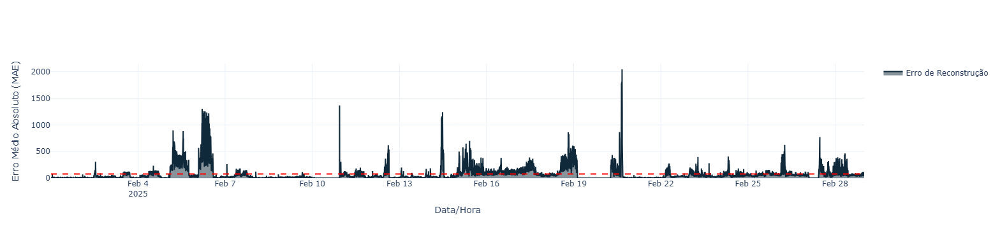

In [83]:
def plot_predict(df_predict, threshold):
    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=df_predict.index,
        y=df_predict['score'],
        mode='lines',
        name='Erro de Reconstrução',
        fill="tozeroy", 
        line=dict(color="#0F293A"),
        connectgaps=False
    ))
    
    fig.add_hline(
        y=threshold, 
        name='Limiar',
        line_dash="dash", 
        line_color="red", 
        line_width=2
    )
    
    fig.update_layout(
        xaxis_title='Data/Hora',
        yaxis_title='Erro Médio Absoluto (MAE)',
        template='plotly_white',
        hovermode="x unified",
        showlegend=True
    )

    return fig

fig = plot_predict(df_predict_omni, threshold)
fig.show()

In [84]:
fig.write_html("output/Detecção-OmniAnomaly_"+ process_name +".html")

## MSCRED

Chuxu Zhang, Dongjin Song, Yuncong Chen, Xinyang Feng, Cristian Lumezanu, Wei Cheng, Jingchao Ni, Bo Zong, Haifeng Chen, and Nitesh V. Chawla. 2019. A deep neural network for unsupervised anomaly detection and diagnosis in multivariate time series data. In Proceedings of the Thirty-Third AAAI Conference on Artificial Intelligence and Thirty-First Innovative Applications of Artificial Intelligence Conference and Ninth AAAI Symposium on Educational Advances in Artificial Intelligence (AAAI'19/IAAI'19/EAAI'19), Vol. 33. AAAI Press, Article 174, 1409–1416. https://doi.org/10.1609/aaai.v33i01.33011409

In [85]:
model_config = {
    'batch_size': 128,
    'sensor_n': df_test.shape[1],
    'win_size': [10, 30, 60],
    'step_max': 5,
    'gap_time': 1,
    'learning_rate': 0.0003,
    'epochs': 5,
    'model_save_path': 'mscred_model/',
    'device': torch.device("cuda" if torch.cuda.is_available() else "cpu")
}

def get_scaler(df_list):
    full_df = pd.concat(df_list, axis=0)
    
    # Transform to (Sensores, Tempo)
    data = np.array(full_df.values.T, dtype=np.float64)
    
    # Global min/max on training set
    max_val = np.max(data, axis=1, keepdims=True)
    min_val = np.min(data, axis=1, keepdims=True)
    
    return min_val, max_val

def generate_signature_matrix(df_block, model_config, scaler_params):
    step_max = model_config['step_max']
    gap_time = model_config['gap_time']
    win_size = model_config['win_size']
    
    # Preprocess
    data = np.array(df_block.values.T, dtype=np.float64)
    sensor_n = data.shape[0]
    total_time = data.shape[1]
    
    # MinMax Normalization
    min_val, max_val = scaler_params
    epsilon = 1e-6
    data = (data - min_val) / (max_val - min_val + epsilon)

    # Generate Signature Matrix
    data_all_scales = []
    for w in range(len(win_size)):
        matrix_list = []
        win = win_size[w]
        
        for t in range(0, total_time, gap_time):
            matrix_t = np.zeros((sensor_n, sensor_n))
            
            # t < win, generate zeros (padding), however the loop ignore this initial zeros
            if t >= win:
                segment = data[:, t - win : t]
                matrix_t = np.matmul(segment, segment.T) / win
            
            matrix_list.append(matrix_t)
        data_all_scales.append(matrix_list)

    # ConvLSTM
    X_block = []
    total_generated_steps = len(data_all_scales[0])
    num_scales = len(win_size)
    
    # Valid sequences when MAIOR JANELA + SEQUÊNCIA HISTÓRICA
    start_idx = (win_size[-1] // gap_time) + step_max

    for i in range(total_generated_steps):
        # Jump cold start
        if i < start_idx:
            continue
            
        sequence_matrices = [] 
        for step in range(step_max, 0, -1):
            idx = i - step
            multi_scale_step = []
            for scale_idx in range(num_scales):
                multi_scale_step.append(data_all_scales[scale_idx][idx])
            sequence_matrices.append(multi_scale_step)
        
        X_block.append(np.array(sequence_matrices))

    if len(X_block) > 0:
        return np.array(X_block)
    else:
        return np.empty((0)) # Retorna vazio se o bloco for muito pequeno


df_train_list = [
    df_train1,
    df_train2,
    df_train3,
    df_train4,
    df_train5,
    df_train6,
    df_train7,
    df_train8,
    df_train9,
    df_train10,
    df_train11,
    df_train12,
    df_train13,
    df_train14
]

df_test_list = [
    df_test
]

# Get scaler values
scaler = get_scaler(df_train_list)

X_train_list = []
for i, block in enumerate(df_train_list):
    print(f"df_train{i+1} shape {len(block)}...")
    X_proc = generate_signature_matrix(block, model_config, scaler)
    
    if X_proc.size > 0:
        X_train_list.append(X_proc)
        print(f" -> {X_proc.shape[0]} sequences.")

if X_train_list:
    X_train_final = np.concatenate(X_train_list, axis=0)
    print(f"\nFinal shape training data: {X_train_final.shape}")

df_train1 shape 1801...
 -> 1736 sequences.
df_train2 shape 4320...
 -> 4255 sequences.
df_train3 shape 60...
df_train4 shape 110...
 -> 45 sequences.
df_train5 shape 120...
 -> 55 sequences.
df_train6 shape 6...
df_train7 shape 20...
df_train8 shape 310...
 -> 245 sequences.
df_train9 shape 30...
df_train10 shape 8...
df_train11 shape 10...
df_train12 shape 120...
 -> 55 sequences.
df_train13 shape 6...
df_train14 shape 80...
 -> 15 sequences.

Final shape training data: (6406, 5, 3, 16, 16)


In [86]:
print(f"Using device: {model_config['device']}")
class MemoryDataset(Dataset):
    def __init__(self, data_array):
        """
        Args:
            data_array: Numpy array with shape (Samples, Steps, Scales, H, W)
        """
        self.data = data_array

    def __len__(self):
        return self.data.shape[0]

    def __getitem__(self, idx):
        # (Steps, Scales, H, W)
        sample = self.data[idx]
        
        # Convert to Tensor float32
        return torch.from_numpy(sample).float()

class ConvLSTMCell(nn.Module):
    def __init__(self, input_dim, hidden_dim, kernel_size, bias):
        super(ConvLSTMCell, self).__init__()
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.kernel_size = kernel_size
        self.padding = kernel_size[0] // 2, kernel_size[1] // 2
        self.bias = bias
        self.conv = nn.Conv2d(in_channels=self.input_dim + self.hidden_dim,
                              out_channels=4 * self.hidden_dim,
                              kernel_size=self.kernel_size,
                              padding=self.padding,
                              bias=self.bias)

    def forward(self, input_tensor, cur_state):
        h_cur, c_cur = cur_state
        combined = torch.cat([input_tensor, h_cur], dim=1)
        combined_conv = self.conv(combined)
        cc_i, cc_f, cc_o, cc_g = torch.split(combined_conv, self.hidden_dim, dim=1)
        i = torch.sigmoid(cc_i)
        f = torch.sigmoid(cc_f)
        o = torch.sigmoid(cc_o)
        g = torch.tanh(cc_g)
        c_next = f * c_cur + i * g
        h_next = o * torch.tanh(c_next)
        return h_next, c_next

    def init_hidden(self, batch_size, image_size, device):
        height, width = image_size
        return (torch.zeros(batch_size, self.hidden_dim, height, width, device=device),
                torch.zeros(batch_size, self.hidden_dim, height, width, device=device))

class TemporalAttention(nn.Module):
    def __init__(self):
        super(TemporalAttention, self).__init__()

    def forward(self, hidden_states):
        # hidden_states: [batch, steps, channels, H, W]
        last_step = hidden_states[:, -1, ...]
        steps = hidden_states.shape[1]
        weights = []
        for k in range(steps):
            curr_step = hidden_states[:, k, ...]
            # Eq (4) Dot Product
            dot_product = torch.sum(curr_step * last_step, dim=(1, 2, 3)) 
            weights.append(dot_product / steps)
        
        weights = torch.stack(weights, dim=1)
        weights = F.softmax(weights, dim=1).unsqueeze(2).unsqueeze(3).unsqueeze(4)
        context = torch.sum(hidden_states * weights, dim=1)
        return context

class MSCRED(nn.Module):
    def __init__(self, sensor_n, scale_n, step_max):
        super(MSCRED, self).__init__()
        self.sensor_n = sensor_n
        
        # Encoder
        self.conv1 = nn.Conv2d(scale_n, 32, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=2, stride=2, padding=0)
        self.conv4 = nn.Conv2d(128, 256, kernel_size=2, stride=2, padding=0)
        
        # ConvLSTMs
        self.lstm1 = ConvLSTMCell(32, 32, (3,3), True)
        self.lstm2 = ConvLSTMCell(64, 64, (3,3), True)
        self.lstm3 = ConvLSTMCell(128, 128, (3,3), True)
        self.lstm4 = ConvLSTMCell(256, 256, (3,3), True)
        
        self.attention = TemporalAttention()
        
        # Decoder
        self.deconv4 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2, padding=0)
        self.deconv3 = nn.ConvTranspose2d(256, 64, kernel_size=2, stride=2, padding=0)
        self.deconv2 = nn.ConvTranspose2d(128, 32, kernel_size=3, stride=2, padding=1)
        self.deconv1 = nn.ConvTranspose2d(64, scale_n, kernel_size=3, stride=1, padding=1)
        
    def forward(self, x):
        b, steps, c, h, w = x.size()
        h1_list, h2_list, h3_list, h4_list = [], [], [], []
        
        # init hidden states in the first loop
        # Calculate expected shapes after convolutions for init_hidden
        dummy_in = torch.zeros(1, c, h, w, device=x.device)
        d1 = self.conv1(dummy_in)
        d2 = self.conv2(d1)
        d3 = self.conv3(d2)
        d4 = self.conv4(d3)
        
        state1 = self.lstm1.init_hidden(b, (d1.size(2), d1.size(3)), x.device)
        state2 = self.lstm2.init_hidden(b, (d2.size(2), d2.size(3)), x.device)
        state3 = self.lstm3.init_hidden(b, (d3.size(2), d3.size(3)), x.device)
        state4 = self.lstm4.init_hidden(b, (d4.size(2), d4.size(3)), x.device)

        for t in range(steps):
            input_t = x[:, t, :, :, :]
            enc1 = F.selu(self.conv1(input_t))
            enc2 = F.selu(self.conv2(enc1))
            enc3 = F.selu(self.conv3(enc2))
            enc4 = F.selu(self.conv4(enc3))
            
            h1, c1 = self.lstm1(enc1, state1)
            state1 = (h1, c1)
            h1_list.append(h1)
            
            h2, c2 = self.lstm2(enc2, state2)
            state2 = (h2, c2)
            h2_list.append(h2)
            
            h3, c3 = self.lstm3(enc3, state3)
            state3 = (h3, c3)
            h3_list.append(h3)
            
            h4, c4 = self.lstm4(enc4, state4)
            state4 = (h4, c4)
            h4_list.append(h4)
            
        h1_stack = torch.stack(h1_list, dim=1)
        h2_stack = torch.stack(h2_list, dim=1)
        h3_stack = torch.stack(h3_list, dim=1)
        h4_stack = torch.stack(h4_list, dim=1)
        
        attn1 = self.attention(h1_stack)
        attn2 = self.attention(h2_stack)
        attn3 = self.attention(h3_stack)
        attn4 = self.attention(h4_stack)
        
        dec4 = F.selu(self.deconv4(attn4))
        if dec4.shape[2:] != attn3.shape[2:]: dec4 = F.interpolate(dec4, size=attn3.shape[2:])
        dec4_concat = torch.cat([dec4, attn3], dim=1)
        
        dec3 = F.selu(self.deconv3(dec4_concat))
        if dec3.shape[2:] != attn2.shape[2:]: dec3 = F.interpolate(dec3, size=attn2.shape[2:])
        dec3_concat = torch.cat([dec3, attn2], dim=1)
        
        dec2 = F.selu(self.deconv2(dec3_concat))
        if dec2.shape[2:] != attn1.shape[2:]: dec2 = F.interpolate(dec2, size=attn1.shape[2:])
        dec2_concat = torch.cat([dec2, attn1], dim=1)
        
        output = F.selu(self.deconv1(dec2_concat))
        return output


def train_model(X_train, model_config):
    device = model_config['device']
    
    if X_train is None or len(X_train) == 0:
        print("X_train is empty!")
        return None

    # Dataset e DataLoader
    dataset = MemoryDataset(X_train)
    dataloader = DataLoader(dataset, batch_size=model_config['batch_size'], shuffle=True)
    
    # Automatically identify dimensions
    # Expected Shape: [Samples, Steps, Scales, H, W]
    sample_shape = X_train.shape
    scale_n = sample_shape[2]
    sensor_n = sample_shape[3] # H = W = sensors
    
    print(f"Init training process... \n(Scales: {scale_n}, Sensors: {sensor_n})")

    model_mscred = MSCRED(sensor_n=sensor_n, scale_n=scale_n, step_max=model_config['step_max']).to(device)
    optimizer = torch.optim.Adam(model_mscred.parameters(), lr=model_config['learning_rate'])
    criterion = nn.MSELoss()
    
    model_mscred.train()
    for epoch in range(model_config['epochs']):
        epoch_loss = 0
        start_time = time.time()
        
        for i, batch_x in enumerate(dataloader):
            batch_x = batch_x.to(device)
            target = batch_x[:, -1, :, :, :] # Target é reconstruir a última matriz
            
            optimizer.zero_grad()
            reconstruction = model_mscred(batch_x)
            
            loss = criterion(reconstruction, target)
            loss.backward()
            optimizer.step()
            
            epoch_loss += loss.item()
            
        avg_loss = epoch_loss / len(dataloader)
        print(f"Epoch [{epoch+1}/{model_config['epochs']}] Loss: {avg_loss:.6f} Time: {time.time()-start_time:.2f}s")
        
    # Save final model
    # torch.save(model_mscred.state_dict(), "mscred_final.pth")
    return model_mscred

def test_model(X_test, model_mscred, model_config):
    device = model_config['device']
    
    if X_test is None or len(X_test) == 0:
        print("X_test vazio.")
        return None
        
    dataset = MemoryDataset(X_test)
    dataloader = DataLoader(dataset, batch_size=model_config['batch_size'], shuffle=False)
    
    model_mscred.eval()
    reconstructions = []
    
    with torch.no_grad():
        for batch_x in dataloader:
            batch_x = batch_x.to(device)
            recon = model_mscred(batch_x)
            reconstructions.append(recon.cpu().numpy())
            
    # Concat batches
    full_recon = np.concatenate(reconstructions, axis=0)
    return full_recon

# Train model
model_mscred = train_model(X_train_final, model_config)

Using device: cpu
Init training process... 
(Scales: 3, Sensors: 16)
Epoch [1/5] Loss: 0.013867 Time: 88.91s
Epoch [2/5] Loss: 0.000681 Time: 92.71s
Epoch [3/5] Loss: 0.000376 Time: 102.16s
Epoch [4/5] Loss: 0.000246 Time: 101.96s
Epoch [5/5] Loss: 0.000176 Time: 100.64s


In [87]:
# Predict
def predict_mscred(df_test, timestamps, model, model_config, scaler_params):
    """
    Gera predições (scores de anomalia) usando o modelo MSCRED e alinha com os timestamps.
    
    Args:
        df_test (pd.DataFrame): Dados brutos de teste.
        timestamps (pd.Series ou list): Eixo X correspondente ao df_test (eixoX_test).
        model (nn.Module): Modelo MSCRED treinado.
        model_config (dict): Dicionário contendo 'gap_time', 'step_max', 'win_size', etc.
        scaler_params (tuple): Tupla (min_val, max_val) obtida no treino.
        
    Returns:
        df_predict (pd.DataFrame): DataFrame indexado pelo tempo contendo a coluna 'score'.
    """
    
    device = next(model.parameters()).device
    
    # Geração de Matrizes
    print("Gerando Matrizes de Assinatura do teste...")
    X_test = generate_signature_matrix(df_test, model_config, scaler_params)
    
    if len(X_test) == 0:
        print("X_test vazio. Nenhum dado gerado.")
        return pd.DataFrame()
        
    # DataLoader
    test_dataset = MemoryDataset(X_test)
    test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)
    
    # Cálculo da Reconstrução
    model.eval()
    batch_scores = []
    with torch.no_grad():
        for i, batch_x in enumerate(test_loader):
            batch_x_gpu = batch_x.to(device)
            
            # Inferência
            recon_gpu = model(batch_x_gpu)
            
            # Cálculo do Erro (Sem guardar a matriz reconstruída)
            # Trazemos de volta para CPU apenas para cálculo do erro
            recon_np = recon_gpu.cpu().numpy()
            original_np = batch_x.numpy() # Já está na CPU pelo DataLoader
            
            # Ground Truth do batch atual (Último passo da sequência)
            # shape: (Batch, Steps, Scales, H, W) -> Pega step -1
            gt_batch = original_np[:, -1, :, :, :]
            
            # Calcula MSE do batch
            # Shape: (Batch, Scales, H, W)
            diff = np.square(gt_batch - recon_np)
            
            # Média sobre eixos (Scales, H, W) -> Resultado: vetor de tamanho (Batch,)
            scores = np.mean(diff, axis=(1, 2, 3))
            
            # Guarda os scores, não as matrizes
            batch_scores.append(scores)
            
            # Limpeza de memória
            del batch_x_gpu, recon_gpu, recon_np, gt_batch, diff
            
    scores_test = np.concatenate(batch_scores, axis=0)
    del X_test
    gc.collect()
    
    # Alinhamento Temporal
    gap_time = model_config['gap_time']
    win_size = model_config['win_size']
    step_max = model_config['step_max']
    
    # Calcular o offset inicial (dados descartados no início)
    start_gap_steps = (win_size[-1] // gap_time) + step_max
    start_index_real = start_gap_steps * gap_time
    
    # Preparar timestamps
    if hasattr(timestamps, 'values'):
        ts_values = timestamps.values
    else:
        ts_values = np.array(timestamps)
        
    # Fatiamento correto: começa no índice real e aplica o passo (gap_time)
    valid_timestamps = ts_values[start_index_real :: gap_time]
    
    # Corte de segurança para garantir tamanhos iguais
    min_len = min(len(scores_test), len(valid_timestamps))
    
    # Criação do DataFrame final
    df_predict = pd.DataFrame({
        'timestamp': valid_timestamps[:min_len],
        'score': scores_test[:min_len]
    })
    df_predict.set_index('timestamp', inplace=True)
    df_predict = df_predict.asfreq('1min')
    df_predict['score'] = df_predict['score'].fillna(0)
    
    return df_predict

df_predict_mscred = predict_mscred(
    df_test=df_test,        # DataFrame bruto
    timestamps=eixoX_test,  # Sua variável separada com datas
    model=model_mscred,    # Modelo carregado
    model_config=model_config,    # Configurações (gap_time, win_size, etc)
    scaler_params=scaler    # (min, max) do treino
)

Gerando Matrizes de Assinatura do teste...


In [88]:
def get_train_scores(X_train, model, batch_size=32):
    """
    Calcula os scores de reconstrução do treino por batch para economizar memória.
    Necessário para definir o limiar sem travar o kernel.
    """
    device = next(model.parameters()).device
    
    # Otimização de tipo
    if X_train.dtype != np.float32:
        X_test = X_train.astype(np.float32)
        
    dataset = MemoryDataset(X_train)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    
    model.eval()
    all_scores = []
    
    with torch.no_grad():
        for batch_x in loader:
            # Envia para GPU
            batch_x_gpu = batch_x.to(device)
            
            # Reconstrói
            recon_gpu = model(batch_x_gpu)
            
            # Traz para CPU para cálculo
            recon_np = recon_gpu.cpu().numpy()
            original_np = batch_x.numpy()
            
            # Pega o Ground Truth (último passo)
            gt_batch = original_np[:, -1, :, :, :]
            
            # Calcula MSE deste batch
            diff = np.square(gt_batch - recon_np)
            
            # Média (Score)
            scores = np.mean(diff, axis=(1, 2, 3))
            
            all_scores.append(scores)
            
            # Limpa memória GPU
            del batch_x_gpu, recon_gpu
            
    return np.concatenate(all_scores, axis=0)

train_scores = get_train_scores(X_train_final, model_mscred, batch_size=128)
percentile = 99 
threshold = np.percentile(train_scores, percentile)

print(f"Média do Score (Treino): {np.mean(train_scores):.6f}")
print(f"Máximo do Score (Treino): {np.max(train_scores):.6f}")
print(f"Limiar Definido (P{percentile}): {threshold:.6f}")

Média do Score (Treino): 0.000155
Máximo do Score (Treino): 0.004600
Limiar Definido (P99): 0.001828


In [89]:
def plot_predict(df_predict, threshold):
    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=df_predict.index,
        y=df_predict['score'],
        mode='lines',
        name='Erro de Reconstrução',
        fill="tozeroy", 
        line=dict(color="#0F293A"),
        connectgaps=False
    ))
    
    fig.add_hline(
        y=threshold, 
        name='Limiar',
        line_dash="dash", 
        line_color="red", 
        line_width=2
    )
    
    fig.update_layout(
        xaxis_title='Data/Hora',
        yaxis_title='Erro Médio Absoluto (MAE)',
        template='plotly_white',
        hovermode="x unified",
        showlegend=True
    )

    return fig

fig = plot_predict(df_predict_mscred, threshold)
fig.show()

In [90]:
fig.write_html("output/Detecção-MSCRED_"+ process_name +".html")

## DAD Framework (CNN with two-stage LSTM-AE)

NIZAM, Hussain et al. Real-time deep anomaly detection framework for multivariate time-series data in industrial IoT. IEEE Sensors Journal, v. 22, n. 23, p. 22836-22849, 2022.

In [91]:
# Configurações do Artigo (Tabela I) 
WINDOW_SIZE = 10
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
EPOCHS = 100
DROPOUT_RATE = 0.1
NUM_CELLS = 50 # Utilizado no paper

# Classe para criar as janelas deslizantes
class TimeSeriesDataset(Dataset):
    def __init__(self, data, window_size):
        self.data = torch.tensor(data, dtype=torch.float32)
        self.window_size = window_size

    def __len__(self):
        return len(self.data) - self.window_size + 1

    def __getitem__(self, idx):
        window = self.data[idx : idx + self.window_size]
        return window, window

def prepare_data(df_train, df_test, cols_to_use):
    # Normalização (Eq. 14 do artigo) [cite: 346]
    scaler = MinMaxScaler()
    
    # Ajustar scaler apenas no treino para evitar data leakage
    train_scaled = scaler.fit_transform(df_train[cols_to_use])
    test_scaled = scaler.transform(df_test[cols_to_use])
    
    # DataLoaders
    train_dataset = TimeSeriesDataset(train_scaled, WINDOW_SIZE)
    test_dataset = TimeSeriesDataset(test_scaled, WINDOW_SIZE)
    
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    return train_loader, test_loader, len(cols_to_use), scaler

cols = df_train.select_dtypes(include=[np.number]).columns.tolist()
train_loader, test_loader, n_features, scaler = prepare_data(df_train, df_test, cols)

In [92]:
class HybridAnomalyDetector(nn.Module):
    def __init__(self, n_features, window_size, dropout_rate=0.1):
        super(HybridAnomalyDetector, self).__init__()
        self.window_size = window_size
        self.n_features = n_features
        
        # CNN Layer (Extração de Features Espaciais) Baseado na Tabela I 
        # Conv1d: (Batch, Channels/Features, Sequence_Length)
        
        self.cnn_block = nn.Sequential(
            # Conv1D (None, 15, 64) - Kernel/Stride configurados para reduzir dimensão
            nn.Conv1d(in_channels=n_features, out_channels=64, kernel_size=2, stride=2, padding=0),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2, stride=1), # (None, 14, 64)
            nn.Dropout(dropout_rate),
            
            # Conv1D (None, 14, 32)
            nn.Conv1d(in_channels=64, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2, stride=1), # (None, 13, 32)
            nn.Dropout(dropout_rate)
        )
        
        # Cálculo dinâmico do tamanho da saída da CNN para entrar na LSTM
        self.feature_map_len = 13 
        self.cnn_output_channels = 32
        
        # Two-Stage LSTM Autoencoder
        # O artigo cita dois LSTMs em paralelo para variações curtas e longas 
        
        # Variações Longas
        self.lstm_stage1 = nn.LSTM(
            input_size=self.cnn_output_channels, 
            hidden_size=NUM_CELLS, 
            batch_first=True,
            bidirectional=False
        )
        
        # Variações Curtas
        self.lstm_stage2 = nn.LSTM(
            input_size=self.cnn_output_channels, 
            hidden_size=NUM_CELLS, 
            batch_first=True,
            bidirectional=False
        )
        
        # Dense / Output Layer
        # Reconstrói para o formato original (Window, Features)
        self.decoder_dense = nn.Sequential(
            nn.Linear(NUM_CELLS * 2, 64), # Tabela I cita Dense 64 
            nn.ReLU(),
            nn.Linear(64, window_size * n_features) 
        )

    def forward(self, x):
        batch_size = x.size(0)
        
        # x shape: (Batch, Window, Features)
        
        # CNN (Batch, Features, Window)
        x_cnn_in = x.permute(0, 2, 1) 
        features = self.cnn_block(x_cnn_in) 
        
        # LSTM (Batch, Seq_Len, Features/Channels)
        lstm_in = features.permute(0, 2, 1)
        
        # Two-Stage LSTM (Paralelo)
        _, (hidden_stage1, _) = self.lstm_stage1(lstm_in)
        _, (hidden_stage2, _) = self.lstm_stage2(lstm_in)
        
        # hidden shape: (1, Batch, Hidden_Size)
        h1 = hidden_stage1[-1]
        h2 = hidden_stage2[-1]
        
        # Combinar Estágios
        combined = torch.cat((h1, h2), dim=1) # (Batch, 100)
        
        # Reconstrução
        reconstruction = self.decoder_dense(combined)
        
        # Reshape para (Batch, Window, Features) para calcular Loss
        reconstruction = reconstruction.view(batch_size, self.window_size, self.n_features)
        
        return reconstruction

In [93]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Usando dispositivo: {device}")

model = HybridAnomalyDetector(n_features=n_features, window_size=WINDOW_SIZE).to(device)

# Função de Perda e Otimizador
criterion = nn.MSELoss() # Baseado na Eq 16 (reconstruction error) [cite: 431]
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

def train_model(model, train_loader, val_loader, epochs):
    model.train()
    for epoch in range(epochs):
        epoch = epoch+1
        train_loss = 0.0
        
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            
            optimizer.zero_grad()
            
            # Forward
            outputs = model(batch_x)
            
            # Loss: Diferença entre a entrada original e a reconstruída
            loss = criterion(outputs, batch_y)
            
            # Backward
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item()
            
        # Validação simples a cada 10 épocas
        if epoch % 10 == 0 or epoch == 1:
            val_loss = 0.0
            model.eval()
            with torch.no_grad():
                for val_x, val_y in val_loader:
                    val_x, val_y = val_x.to(device), val_y.to(device)
                    v_out = model(val_x)
                    val_loss += criterion(v_out, val_y).item()
            model.train()
            print(f"Epoch {epoch}/{epochs}, Train Loss: {train_loss/len(train_loader):.4f}, Val Loss: {val_loss/len(val_loader):.4f}")

# Treino
train_model(model, train_loader, test_loader, EPOCHS)

Usando dispositivo: cpu
Epoch 1/100, Train Loss: 0.0926, Val Loss: 0.0154
Epoch 10/100, Train Loss: 0.0051, Val Loss: 0.0104
Epoch 20/100, Train Loss: 0.0034, Val Loss: 0.0091
Epoch 30/100, Train Loss: 0.0029, Val Loss: 0.0082
Epoch 40/100, Train Loss: 0.0027, Val Loss: 0.0073
Epoch 50/100, Train Loss: 0.0026, Val Loss: 0.0070
Epoch 60/100, Train Loss: 0.0025, Val Loss: 0.0066
Epoch 70/100, Train Loss: 0.0024, Val Loss: 0.0064
Epoch 80/100, Train Loss: 0.0023, Val Loss: 0.0060
Epoch 90/100, Train Loss: 0.0022, Val Loss: 0.0061
Epoch 100/100, Train Loss: 0.0021, Val Loss: 0.0064


In [94]:
# Predict
def get_anomaly_scores(model, loader):
    model.eval()
    losses = []
    with torch.no_grad():
        for batch_x, _ in loader:
            batch_x = batch_x.to(device)
            reconstruction = model(batch_x)
            
            # Calcular erro MAE ou MSE por amostra (Eq 17/18) [cite: 434]
            # Aqui calculamos a média do erro absoluto por janela
            error = torch.mean(torch.abs(reconstruction - batch_x), dim=(1, 2))
            losses.extend(error.cpu().numpy())
            
    return np.array(losses)

train_scores = get_anomaly_scores(model, train_loader)
test_scores = get_anomaly_scores(model, test_loader)

# Definir Threshold (ex: média + 3*std do treino)
threshold = np.mean(train_scores) + 5 * np.std(train_scores)

In [95]:
# Predict
def predict_dad(df_test, timestamps, modelo, scaler, batch_size=128, device=None):
    """
    Realiza a predição de anomalias utilizando a classe TimeSeriesDataset para criar as janelas.
    
    Args:
        df_test (pd.DataFrame): Dados de teste.
        timestamps (pd.Series ou array): Eixo temporal correspondente.
        modelo (nn.Module): Modelo treinado.
        scaler (MinMaxScaler): Scaler ajustado no treino.
        batch_size (int): Tamanho do lote.
        device (torch.device): Dispositivo de processamento.
        
    Returns:
        pd.DataFrame: DataFrame com timestamp no índice e coluna 'loss'.
    """
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    modelo.to(device)
    modelo.eval()
    
    # Pré-processamento e Escalonamento
    try:
        X_test_scaled = scaler.transform(df_test)
    except ValueError:
        X_test_scaled = scaler.transform(df_test.values)

    dataset = TimeSeriesDataset(X_test_scaled, modelo.window_size)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    
    all_losses = []
    with torch.no_grad():
        for batch_input, _ in loader:
            inputs = batch_input.to(device)
            
            # Forward pass
            reconstruction = modelo(inputs)
            
            # Cálculo do Erro de Reconstrução (MAE por janela) (Batch, Janela, Features)
            batch_loss = torch.mean(torch.abs(reconstruction - inputs), dim=[1, 2])
            all_losses.extend(batch_loss.cpu().numpy())

    if hasattr(timestamps, 'values'):
        ts_values = timestamps.values
    else:
        ts_values = np.array(timestamps)
    
    valid_timestamps = ts_values[modelo.window_size - 1 :]
    
    min_len = min(len(all_losses), len(valid_timestamps))
    
    df_predict = pd.DataFrame({
        'timestamp': valid_timestamps[:min_len],
        'loss': all_losses[:min_len]
    })
    df_predict.set_index('timestamp', inplace=True)
    df_predict = df_predict.asfreq('1min')
    df_predict['loss'] = df_predict['loss'].fillna(0)
    
    return df_predict

df_predict_dad = predict_dad(
    df_test=df_test,        # Seu DataFrame de teste
    timestamps=eixoX_test,  # Seus timestamps
    modelo=model,           # Seu modelo treinado
    scaler=scaler,          # Scaler treinado (retornado pelo prepare_data)
    batch_size=BATCH_SIZE
)

In [96]:
def plot_predict(df_predict, threshold):
    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=df_predict.index,
        y=df_predict['loss'],
        mode='lines',
        name='Erro de Reconstrução',
        fill="tozeroy", 
        line=dict(color="#0F293A"),
        connectgaps=False
    ))
    
    fig.add_hline(
        y=threshold, 
        name='Limiar',
        line_dash="dash", 
        line_color="red", 
        line_width=2
    )
    
    fig.update_layout(
        xaxis_title='Data/Hora',
        yaxis_title='Erro Médio Absoluto (MAE)',
        template='plotly_white',
        hovermode="x unified",
        showlegend=True
    )

    return fig

fig = plot_predict(df_predict_dad, threshold)
fig.show()

In [97]:
fig.write_html("output/Detecção-DAD_"+ process_name +".html")

## Attention-Based Deep Convolutional Autoencoding Prediction Network (AT-DCAEP)

Liu, W., Yan, L., Ma, N., Wang, G., Ma, X., Liu, P., & Tang, R. (2024). Unsupervised deep anomaly detection for industrial multivariate time series data. Applied Sciences, 14(2), 774.

In [98]:
class ExternalAttention(nn.Module):
    def __init__(self, d_model, S=64):
        super(ExternalAttention, self).__init__()
        self.mk = nn.Linear(d_model, S, bias=False) # Primeira camada linear (Memory Key)
        self.mv = nn.Linear(S, d_model, bias=False) # Segunda camada linear (Memory Value)
        self.softmax = nn.Softmax(dim=1) # Normalization [cite: 290]

    def forward(self, x):
        # Eq 16: A = Norm(O * M_k^T)
        attn = self.mk(x) # (Batch, Time, S)
        attn = self.softmax(attn) # Normalização da atenção
        
        # Eq 17: P_out = A * M_v
        attn = attn / (1e-9 + attn.sum(dim=-1, keepdim=True)) # Normalização adicional
        out = self.mv(attn) # (Batch, Time, d_model)
        return out

class CharacterizationNetwork(nn.Module):
    """
    Rede de Caracterização baseada em Autoencoder Convolucional + Multi-Head Attention.
    """
    def __init__(self, n_features, window_size=11):
        super(CharacterizationNetwork, self).__init__()
        
        # Encoder
        self.enc_conv1 = nn.Conv1d(n_features, 32, kernel_size=3, stride=2, padding=1) # [cite: 206-209]
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.2) # [cite: 207]
        self.enc_conv2 = nn.Conv1d(32, 16, kernel_size=3, stride=2, padding=1) # [cite: 161]
        
        # Low-Dimensional Feature Extraction [cite: 212]
        self.multihead_attn = nn.MultiheadAttention(embed_dim=16, num_heads=4, batch_first=True)
        
        # Decoder
        self.dec_conv1 = nn.ConvTranspose1d(16, 32, kernel_size=3, stride=2, padding=1, output_padding=0) # [cite: 158]
        self.dec_conv2 = nn.ConvTranspose1d(32, n_features, kernel_size=3, stride=2, padding=1, output_padding=1) # [cite: 155]
        
        self.window_size = window_size

    def forward(self, x):
        x = x.permute(0, 2, 1) # (Batch, Features, Window)
        
        # --- ENCODER ---
        x_enc = self.relu(self.enc_conv1(x))
        x_enc = self.dropout(x_enc)
        D = self.relu(self.enc_conv2(x_enc))
        
        # --- LOW-DIMENSIONAL FEATURE EXTRACTION ---
        D_perm = D.permute(0, 2, 1) 
        D_prime, _ = self.multihead_attn(D_perm, D_perm, D_perm)
        D_prime = D_prime.permute(0, 2, 1)
        
        # --- DECODER ---
        x_dec = self.relu(self.dec_conv1(D_prime))
        x_dec = self.dropout(x_dec)
        S_prime = self.dec_conv2(x_dec)
        
        # Ajuste fino de tamanho (interpolação)
        if S_prime.shape[2] != self.window_size:
            S_prime = F.interpolate(S_prime, size=self.window_size, mode='linear', align_corners=False)
            
        S_prime = S_prime.permute(0, 2, 1) # (Batch, Window, Feat)
        return S_prime, D_prime

class PredictionNetwork(nn.Module):
    """
    Rede de Predição baseada em Atenção (LSTM + External Attention).
    """
    def __init__(self, n_features, latent_dim=16):
        super(PredictionNetwork, self).__init__()
        
        # Downsampling [cite: 240]
        self.conv_down = nn.Conv1d(n_features, latent_dim, kernel_size=1, stride=4) 
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.2)
        
        # Upsampling [cite: 250]
        self.conv_up = nn.ConvTranspose1d(latent_dim, latent_dim, kernel_size=1, stride=4, output_padding=0)
        
        # LSTM [cite: 254]
        self.lstm = nn.LSTM(input_size=latent_dim, hidden_size=32, batch_first=True)
        
        # External Attention [cite: 285]
        self.external_attn = ExternalAttention(d_model=32, S=64)
        
        self.final_proj = nn.Linear(32, n_features)

    def forward(self, R, D_prime, target_len):
        R_in = R.permute(0, 2, 1)
        
        # Eq 8: D' (fused) = Downsample(R) + D'
        R_down = self.relu(self.conv_down(R_in))
        
        if R_down.shape[2] != D_prime.shape[2]:
             R_down = F.interpolate(R_down, size=D_prime.shape[2])
             
        R_prime = R_down + D_prime # Fusão [cite: 246, 251]
        
        # Eq 9: E = Upsample(R')
        E = self.conv_up(R_prime)
        
        if E.shape[2] != target_len:
            E = F.interpolate(E, size=target_len, mode='linear', align_corners=False)
            
        E = E.permute(0, 2, 1)
        
        # LSTM & External Attention
        lstm_out, _ = self.lstm(E)
        lstm_out = self.dropout(lstm_out)
        attn_out = self.external_attn(lstm_out) # Eq 17
        
        P_out = self.final_proj(attn_out)
        return P_out

class AT_DCAEP(nn.Module):
    def __init__(self, n_features, window_size=11):
        super(AT_DCAEP, self).__init__()
        self.characterization_net = CharacterizationNetwork(n_features, window_size)
        self.prediction_net = PredictionNetwork(n_features)
        self.window_size = window_size

    def forward(self, S):
        S_prime, D_prime = self.characterization_net(S)
        
        # Calcular Erro de Reconstrução R [cite: 147]
        R = (S - S_prime) ** 2 
        
        P_out = self.prediction_net(R, D_prime, self.window_size)
        return S_prime, P_out, R

def loss_function(S, S_prime, R, P_out):
    """ Eq 19: L = ||S - S'||2 + ||R - P_out||2 [cite: 302] """
    loss_reconstruction = F.mse_loss(S_prime, S)
    loss_prediction = F.mse_loss(P_out, R)
    return loss_reconstruction + loss_prediction

def create_sliding_window(data, window_size):
    samples = []
    for i in range(len(data) - window_size + 1):
        samples.append(data[i : i + window_size])
    return np.array(samples)

def prepare_data(df_train, df_test, window_size=11):
    # Instancia o Scaler
    scaler = MinMaxScaler()
    
    # Fit apenas no treino
    if hasattr(df_train, 'values'):
        train_data = scaler.fit_transform(df_train.values)
        test_data = scaler.transform(df_test.values)
    else:
        train_data = scaler.fit_transform(df_train)
        test_data = scaler.transform(df_test)

    # Janelamento
    X_train = create_sliding_window(train_data, window_size)
    X_test = create_sliding_window(test_data, window_size)

    # Conversão para Tensor
    tensor_train = torch.FloatTensor(X_train)
    tensor_test = torch.FloatTensor(X_test)
    
    return tensor_train, tensor_test, scaler

def train_model(model, train_loader, num_epochs=50, learning_rate=1e-3):
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    print(f"Iniciando treinamento em: {device}")

    model.train()

    # Loop de Treinamento (Algoritmo 1) [cite: 325]
    for epoch in range(num_epochs):
        epoch = epoch+1
        start_time = time.time()
        total_loss = 0
        
        for batch_idx, (data,) in enumerate(train_loader):
            data = data.to(device)
            optimizer.zero_grad()
            
            # Forward & Loss
            S_prime, P_out, R = model(data)
            loss = loss_function(data, S_prime, R, P_out) # [cite: 302]
            
            # Backward
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        end_time = time.time()
        print(f"Epoch [{epoch}/{num_epochs}] | Loss: {avg_loss:.6f} | Tempo: {end_time - start_time:.2f}s")
        
    return model

def calculate_threshold(model, tensor_train, alpha=0.3, beta=0.7, gain=3):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.eval()
    
    train_dataset = TensorDataset(tensor_train)
    train_loader = DataLoader(train_dataset, batch_size=256, shuffle=False)
    
    train_scores = []
    
    with torch.no_grad():
        for (data,) in train_loader:
            data = data.to(device)
            
            # Forward Pass
            S_prime, P_out, R = model(data)
            
            # [cite_start]Eq 20 [cite: 318]
            loss_rec = torch.norm(data - S_prime, p=2, dim=(1,2))
            loss_pred = torch.norm(R - P_out, p=2, dim=(1,2))
            
            score = alpha * loss_rec + beta * loss_pred
            train_scores.extend(score.cpu().numpy())

    threshold = np.mean(train_scores) + gain * np.std(train_scores)
    print(f"Threshold : {threshold:.4f}")
    
    return threshold

In [99]:
# Parâmetros
BATCH_SIZE = 128
window_size = 10
n_features = df_train.shape[1]
EPOCHS = 10
LR = 1e-3

print(f"Configuração: Features={n_features}, Window={window_size}, Batch={BATCH_SIZE}")

# Preparação dos Dados
tensor_train, tensor_test, scaler = prepare_data(df_train, df_test, window_size=window_size)

train_dataset = TensorDataset(tensor_train)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

# Treino
model_atdcaep = AT_DCAEP(n_features=n_features, window_size=window_size)
model_atdcaep = train_model(model_atdcaep, train_loader, num_epochs=EPOCHS, learning_rate=LR)

threshold = calculate_threshold(model_atdcaep, tensor_train, alpha=0.3, beta=0.7, gain=3)

Configuração: Features=16, Window=10, Batch=128
Iniciando treinamento em: cpu
Epoch [1/10] | Loss: 0.155810 | Tempo: 0.56s
Epoch [2/10] | Loss: 0.033044 | Tempo: 0.53s
Epoch [3/10] | Loss: 0.027196 | Tempo: 0.53s
Epoch [4/10] | Loss: 0.024977 | Tempo: 0.53s
Epoch [5/10] | Loss: 0.023674 | Tempo: 0.54s
Epoch [6/10] | Loss: 0.022288 | Tempo: 0.53s
Epoch [7/10] | Loss: 0.019526 | Tempo: 0.54s
Epoch [8/10] | Loss: 0.017987 | Tempo: 0.54s
Epoch [9/10] | Loss: 0.016207 | Tempo: 0.54s
Epoch [10/10] | Loss: 0.015514 | Tempo: 0.53s
Threshold : 1.6405


In [100]:
# Predict
def predict_atdcaep(df_test, timestamps, modelo, scaler, alpha=0.3, beta=0.7, batch_size=128, device=None):
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    modelo.to(device)
    modelo.eval()
    
    # Scalling
    try:
        if hasattr(df_test, 'values'):
            data_values = df_test.values
        else:
            data_values = df_test
        
        X_test_scaled = scaler.transform(data_values)
    except Exception as e:
        print(f"Erro no scaler: {e}. Usando dados brutos (não recomendado).")
        X_test_scaled = data_values

    # Janelamento
    window_size = modelo.window_size
    samples = []
    for i in range(len(X_test_scaled) - window_size + 1):
        samples.append(X_test_scaled[i : i + window_size])
    
    if len(samples) == 0:
        raise ValueError("O DataFrame de teste é menor que o tamanho da janela.")

    X_test_windowed = np.array(samples)
    tensor_test = torch.FloatTensor(X_test_windowed)
    loader = DataLoader(TensorDataset(tensor_test), batch_size=batch_size, shuffle=False)
    
    all_scores = []
    with torch.no_grad():
        for (batch_input,) in loader:
            inputs = batch_input.to(device)
            S_prime, P_out, R = modelo(inputs)
            
            loss_rec = torch.norm(inputs - S_prime, p=2, dim=(1,2))
            loss_pred = torch.norm(R - P_out, p=2, dim=(1,2))
            
            batch_scores = alpha * loss_rec + beta * loss_pred
            all_scores.extend(batch_scores.cpu().numpy())

    # Alinhamento Temporal
    if hasattr(timestamps, 'values'):
        ts_values = timestamps.values
    else:
        ts_values = np.array(timestamps)
    
    valid_timestamps = ts_values[window_size - 1 :]
    min_len = min(len(all_scores), len(valid_timestamps))
    
    # DataFrame Final
    df_predict = pd.DataFrame({
        'timestamp': valid_timestamps[:min_len],
        'loss': all_scores[:min_len]
    })
    df_predict.set_index('timestamp', inplace=True)
    df_predict = df_predict.asfreq('1min')
    df_predict['loss'] = df_predict['loss'].fillna(0)
    
    return df_predict

df_predict_atdcaep = predict_atdcaep(
    df_test=df_test,        # DataFrame original de teste
    timestamps=eixoX_test,  # Series com timestamps
    modelo=model_atdcaep,           # Modelo AT-DCAEP treinado
    scaler=scaler,          # Scaler treinado
    alpha=0.3, 
    beta=0.7,
    batch_size=BATCH_SIZE
)

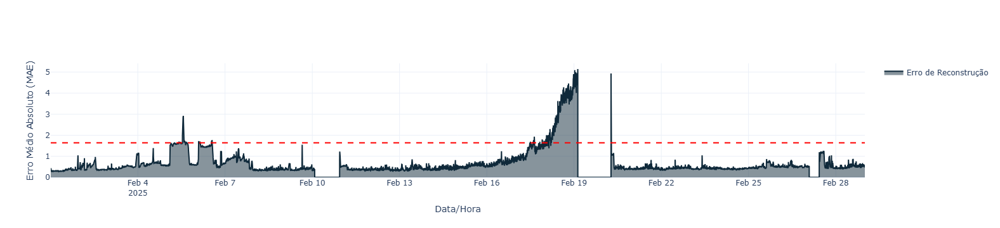

In [101]:
def plot_predict(df_predict, threshold):
    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=df_predict.index,
        y=df_predict['loss'],
        mode='lines',
        name='Erro de Reconstrução',
        fill="tozeroy", 
        line=dict(color="#0F293A"),
        connectgaps=False
    ))
    
    fig.add_hline(
        y=threshold, 
        name='Limiar',
        line_dash="dash", 
        line_color="red", 
        line_width=2
    )
    
    fig.update_layout(
        xaxis_title='Data/Hora',
        yaxis_title='Erro Médio Absoluto (MAE)',
        template='plotly_white',
        hovermode="x unified",
        showlegend=True
    )

    return fig

fig = plot_predict(df_predict_atdcaep, threshold)
fig.show()

In [102]:
fig.write_html("output/Detecção-ATDCAEP_"+ process_name +".html")

## Robust Unsupervised Anomaly Detection With Variational Autoencoder in Multivariate Time Series Data (MSCVAE)

Yokkampon, U., Mowshowitz, A., Chumkamon, S., & Hayashi, E. (2022). Robust unsupervised anomaly detection with variational autoencoder in multivariate time series data. IEEE Access, 10, 57835-57849.

In [21]:
class AttributeMatrixGenerator:
    def __init__(self, window_size=10, step=10):
        # [cite_start]O paper define w=10 e intervalo=10 [cite: 153, 154]
        self.w = window_size
        self.step = step
        # Armazena estatísticas de normalização
        self.mean = None
        self.std = None

    def fit_scaler(self, train_dataframes):
        """
        Calcula média e desvio padrão global a partir de uma lista de DataFrames de treino.
        
        Args:
            train_dataframes (list of pd.DataFrame): Lista contendo [df_train1, df_train2, ...]
        """
        # Concatena todos os dfs de treino apenas para calcular as estatísticas globais
        full_train_df = pd.concat(train_dataframes, ignore_index=True)
        
        self.mean = full_train_df.mean()
        self.std = full_train_df.std() + 1e-6 # Evita divisão por zero

    def generate(self, df):
        """
        Gera as matrizes de atributos usando a normalização aprendida no fit.
        """
        if self.mean is None or self.std is None:
            raise ValueError("O gerador não foi treinado. Execute .fit_scaler([df_train1, ...]) antes de gerar matrizes.")

        # Normalização usando as estatísticas do TREINO (crucial para validação correta)
        # Alinha as colunas para garantir que estamos subtraindo a média da feature correta
        try:
            data = (df - self.mean) / self.std
        except ValueError as e:
            print(f"Erro na normalização: Verifique se as colunas do df batem com o treino. {e}")
            raise

        values = data.values
        # Se houver NaN após normalização (ex: desvio padrão zero), preenche com 0
        values = np.nan_to_num(values) 
        
        matrices = []
        
        # Janela deslizante
        # Se o dataframe for menor que a janela, retorna tensor vazio ou lida conforme necessário
        if len(values) < self.w:
            return torch.empty(0)

        for t in range(self.w, len(values), self.step):
            # Segmento X: [w, n]
            x_segment = values[t-self.w : t] 
            
            # Eq. 1: Produto interno par-a-par dividido por w 
            # (n, w) @ (w, n) -> (n, n)
            x_t = torch.tensor(x_segment, dtype=torch.float32).T
            m_t = torch.matmul(x_t, x_t.T) / self.w
            matrices.append(m_t)
            
        if not matrices:
            return torch.empty(0)

        # Formato final: (Batch, Channels=1, N, N)
        return torch.stack(matrices).unsqueeze(1)

class TemporalAttention(nn.Module):
    def __init__(self, hidden_dim):
        super(TemporalAttention, self).__init__()
        self.scale = 5.0 # Chi = 5 conforme definido no paper [cite: 249]

    def forward(self, h_current, h_history):
        # h_current: (B, C, H, W) -> hidden state atual
        # h_history: Lista de hidden states passados
        if not h_history:
            return h_current
        
        # Empilha histórico: (Time, B, C, H, W)
        context = torch.stack(h_history, dim=0)
        
        # Eq. 7: Score s^t = (H^t . H^i) / chi [cite: 248]
        # Atenção baseada em produto escalar achatado
        b, c, h, w = h_current.size()
        flat_curr = h_current.view(b, -1).unsqueeze(1) # (B, 1, Features)
        flat_hist = context.view(context.size(0), b, -1).permute(1, 2, 0) # (B, Features, Time)
        
        scores = torch.bmm(flat_curr, flat_hist) / self.scale # (B, 1, Time)
        weights = F.softmax(scores, dim=-1) # Eq. 6 [cite: 247]
        
        # Eq. 5: Soma ponderada [cite: 245]
        # (B, 1, Time) @ (B, Time, Features) -> (B, 1, Features)
        weighted_hist = torch.bmm(weights, flat_hist.permute(0, 2, 1))
        h_hat = weighted_hist.view(b, c, h, w)
        
        return h_hat

class ConvLSTMCell(nn.Module):
    def __init__(self, input_dim, hidden_dim, kernel_size, bias):
        super(ConvLSTMCell, self).__init__()
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.padding = kernel_size // 2
        
        self.conv = nn.Conv2d(in_channels=input_dim + hidden_dim,
                              out_channels=4 * hidden_dim,
                              kernel_size=kernel_size,
                              padding=self.padding,
                              bias=bias)

    def forward(self, input_tensor, cur_state):
        h_cur, c_cur = cur_state
        combined = torch.cat([input_tensor, h_cur], dim=1)
        combined_conv = self.conv(combined)
        cc_i, cc_f, cc_o, cc_g = torch.split(combined_conv, self.hidden_dim, dim=1)
        
        i = torch.sigmoid(cc_i)
        f = torch.sigmoid(cc_f)
        o = torch.sigmoid(cc_o)
        g = torch.tanh(cc_g)
        
        c_next = f * c_cur + i * g
        h_next = o * torch.tanh(c_next)
        return h_next, c_next

class MSCVAE(nn.Module):
    def __init__(self, n_features, latent_dim=20):
        super(MSCVAE, self).__init__()
        self.n_features = n_features
        
        # [cite_start]--- Encoder (Convolutional) [cite: 178] ---
        # Assume input (1, N, N)
        self.enc1 = nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1)
        self.enc2 = nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1)
        self.enc3 = nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1)
        
        with torch.no_grad():
            # Cria um tensor dummy com o shape (Batch=1, Channel=1, H=n_features, W=n_features)
            dummy_input = torch.zeros(1, 1, n_features, n_features)
            dummy_out = self.enc3(self.enc2(self.enc1(dummy_input)))
            
            # Pega o número total de features achatadas (ex: 64 * 4 * 4 = 1024)
            self.flatten_dim = dummy_out.view(1, -1).size(1)
            # Salva o shape espacial para usar no decoder (ex: 64, 4, 4)
            self.spatial_shape = dummy_out.shape[1:] 

        # Variáveis latentes (Mean & LogVar)
        self.fc_mu = nn.Linear(self.flatten_dim, latent_dim)
        self.fc_logvar = nn.Linear(self.flatten_dim, latent_dim)
        self.fc_decode = nn.Linear(latent_dim, self.flatten_dim)
        
        # Temporal Modeling (ConvLSTM + Attention)
        # Usamos ConvLSTM no bottleneck/nível mais profundo conforme Fig 1 (b)-(c)
        self.clstm = ConvLSTMCell(64, 64, kernel_size=3, bias=True)
        self.attention = TemporalAttention(hidden_dim=64)
        
        # [cite_start]--- Decoder (Deconvolutional) [cite: 254] ---
        self.dec3 = nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1)
        self.dec2 = nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=1)
        self.dec1 = nn.ConvTranspose2d(16, 1, kernel_size=3, stride=2, padding=1, output_padding=1)
        
        # Estado interno para LSTM e histórico para atenção
        self.h_state = None
        self.c_state = None
        self.history = []
        self.max_history = 5 # Janela de atenção (h na Eq. 5)

    def reparameterize(self, mu, logvar):
        if self.training:
            std = torch.exp(0.5 * logvar)
            return mu + torch.randn_like(std) * std
        else:
            return mu

    def forward(self, x):
        batch_size = x.size(0)
        
        # Encoding
        e1 = F.relu(self.enc1(x))
        e2 = F.relu(self.enc2(e1))
        e3 = F.relu(self.enc3(e2)) # Feature map mais profunda (P^t,l)
        
        # VAE Bottleneck
        flat = e3.view(batch_size, -1)
        mu = self.fc_mu(flat)
        logvar = self.fc_logvar(flat)
        z = self.reparameterize(mu, logvar)
        
        # [cite_start]3. Temporal Modeling (Attention-based ConvLSTM) [cite: 242, 245]
        if self.h_state is None or self.h_state.size(0) != batch_size:
            h, w = self.spatial_shape[1], self.spatial_shape[2]
            self.h_state = torch.zeros(batch_size, 64, h, w).to(x.device)
            self.c_state = torch.zeros(batch_size, 64, h, w).to(x.device)
            self.history = []

        # Aplica ConvLSTM na feature map latente
        h_next, c_next = self.clstm(e3, (self.h_state, self.c_state))
        
        # Aplica Atenção no histórico
        h_att = self.attention(h_next, self.history)
        
        # Atualiza estados
        self.h_state = h_att.detach() 
        self.c_state = c_next.detach()
        self.history.append(self.h_state)
        if len(self.history) > self.max_history:
            self.history.pop(0)

        # [cite_start]4. Decoding [cite: 262]
        z_dec = self.fc_decode(z)
        # Reshape usando as dimensões espaciais calculadas dinamicamente
        z_dec = z_dec.view(batch_size, *self.spatial_shape)
        
        combined_features = z_dec + h_att 
        
        d3 = F.relu(self.dec3(combined_features))
        d2 = F.relu(self.dec2(d3))
        recon_x = self.dec1(d2)
        
        if recon_x.shape != x.shape:
            recon_x = F.interpolate(recon_x, size=x.shape[2:], mode='bilinear', align_corners=False)

        return recon_x, mu, logvar

    def loss_function(self, recon_x, x, mu, logvar):
        # Eq. [cite_start]2 e 9: MSE + KL Divergence [cite: 173, 268]
        MSE = F.mse_loss(recon_x, x, reduction='sum')
        KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
        return MSE + KLD

def train_model(model, train_loader, epochs=50):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    model.train()
    
    for epoch in range(epochs):
        epoch=epoch+1
        total_loss = 0
        for batch in train_loader:
            x = batch[0]
            
            optimizer.zero_grad()
            recon_x, mu, logvar = model(x)
            loss = model.loss_function(recon_x, x, mu, logvar)
            loss.backward()
            optimizer.step()
            
            total_loss += loss.item()
        
        print(f"Epoch {epoch} | Loss: {total_loss / len(train_loader.dataset):.4f}")

def get_anomaly_scores(model, data_tensor):
    model.eval()
    mse_loss = nn.MSELoss(reduction='none')
    scores = []
    
    with torch.no_grad():
        model.h_state = None
        model.history = []
        
        # Processar sequencialmente para manter memória temporal
        for i in range(data_tensor.size(0)):
            x = data_tensor[i].unsqueeze(0)
            recon_x, _, _ = model(x)
            # Score é o erro de reconstrução
            loss = mse_loss(recon_x, x).sum().item()
            scores.append(loss)
            
    return np.array(scores)

def calculate_threshold(scores, gain=3):    
    mu = np.mean(scores)
    sigma = np.std(scores)
    threshold = mu + (gain * sigma)
    
    print(f"Threshold: {threshold:.4f}")
    return threshold

In [22]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
WINDOW_SIZE = 10
STRIDE = 1
BATCH_SIZE = 128
N_FEATURES = df_train.shape[1]
EPOCHS = 15

generator = AttributeMatrixGenerator(window_size=WINDOW_SIZE, step=STRIDE)
dfs_treino = [df_train1, df_train2, df_train3, df_train4, df_train5, df_train6, df_train7, df_train8, df_train9, df_train10, df_train11, df_train12, df_train13, df_train14]
generator.fit_scaler(dfs_treino)

train_tensors = []
for df in dfs_treino:
    t = generator.generate(df)
    if t.nelement() > 0:
        train_tensors.append(t)
final_train_tensor = torch.cat(train_tensors, dim=0)
train_loader = DataLoader(TensorDataset(final_train_tensor), batch_size=BATCH_SIZE, shuffle=True)

# Instanciar modelo
n_vars = N_FEATURES
model_mscvae = MSCVAE(n_features=n_vars)

# Treino
train_model(model_mscvae, train_loader,epochs=EPOCHS)
train_scores = get_anomaly_scores(model_mscvae, final_train_tensor)
threshold = calculate_threshold(train_scores, gain=5)

Epoch 1 | Loss: 584.3822
Epoch 2 | Loss: 424.8623
Epoch 3 | Loss: 266.9064
Epoch 4 | Loss: 158.0978
Epoch 5 | Loss: 123.9659
Epoch 6 | Loss: 105.7929
Epoch 7 | Loss: 95.3296
Epoch 8 | Loss: 87.0433
Epoch 9 | Loss: 81.2875
Epoch 10 | Loss: 76.4926
Epoch 11 | Loss: 70.1667
Epoch 12 | Loss: 68.2560
Epoch 13 | Loss: 65.8660
Epoch 14 | Loss: 64.6416
Epoch 15 | Loss: 60.3542
Threshold: 482.2904


In [23]:
# Predict
def predict_mscvae(df_test, timestamps, model, generator, batch_size=128, device=None):
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    model.to(device)
    model.eval()
    
    tensor_test = generator.generate(df_test)
    loader = DataLoader(TensorDataset(tensor_test), batch_size=batch_size, shuffle=False)
    
    mse_loss = nn.MSELoss(reduction='none')
    all_scores = []
    
    # Inferência
    with torch.no_grad():
        model.h_state = None
        model.c_state = None
        model.history = []
        
        for (batch_input,) in loader:
            inputs = batch_input.to(device)
            
            # Forward pass
            recon_x, mu, logvar = model(inputs)
            
            # Cálculo do Score: MSE por amostra
            # inputs shape: (B, 1, N, N)
            # sum((recon - input)^2) -> reduz dimensões (1, 2, 3) mantendo o batch
            loss_batch = mse_loss(recon_x, inputs).sum(dim=(1, 2, 3))
            
            all_scores.extend(loss_batch.cpu().numpy())

    # Alinhamento Temporal
    # O generator produz matrizes começando no índice 'window_size' e pulando a cada 'step'
    w = generator.w
    s = generator.step
    

    if hasattr(timestamps, 'values'):
        ts_values = timestamps.values
    else:
        ts_values = np.array(timestamps)

    valid_indices = range(w, len(df_test) + 1, s) # +1 para incluir o último ponto se divisível exato
    min_len = min(len(all_scores), len(valid_indices))
    
    final_scores = all_scores[:min_len]
    final_indices = valid_indices[:min_len]
    
    final_timestamps = []
    for idx in final_indices:
        if idx < len(ts_values):
             final_timestamps.append(ts_values[idx])
        elif idx == len(ts_values):
            final_timestamps.append(ts_values[-1])
    final_scores = final_scores[:len(final_timestamps)]
    
    # DataFrame
    df_predict = pd.DataFrame({
        'timestamp': final_timestamps,
        'loss': final_scores
    })
    df_predict.set_index('timestamp', inplace=True)
    df_predict = df_predict.asfreq('1min')
    df_predict['loss'] = df_predict['loss'].fillna(0)
    
    return df_predict

df_predict_mscvae = predict_mscvae(
    df_test=df_test,            # Seu DataFrame de teste
    timestamps=eixoX_test,      # Série de timestamps
    model=model_mscvae,         # Modelo treinado
    generator=generator,        # Instância do generator
    batch_size=BATCH_SIZE,
    device=DEVICE
)

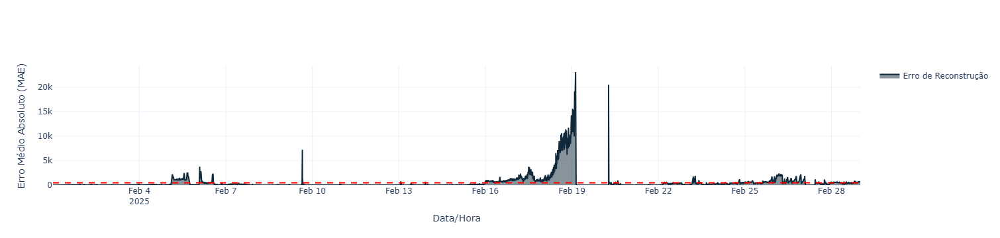

In [24]:
def plot_predict(df_predict, threshold):
    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=df_predict.index,
        y=df_predict['loss'],
        mode='lines',
        name='Erro de Reconstrução',
        fill="tozeroy", 
        line=dict(color="#0F293A"),
        connectgaps=False
    ))
    
    fig.add_hline(
        y=threshold, 
        name='Limiar',
        line_dash="dash", 
        line_color="red", 
        line_width=2
    )
    
    fig.update_layout(
        xaxis_title='Data/Hora',
        yaxis_title='Erro Médio Absoluto (MAE)',
        template='plotly_white',
        hovermode="x unified",
        showlegend=True
    )

    return fig

fig = plot_predict(df_predict_mscvae, threshold)
fig.show()

In [25]:
fig.write_html("output/Detecção-MSCVAE_"+ process_name +".html")

## TranAD: Deep Transformer Networks for Anomaly Detection in Multivariate Time Series Data

Tuli, S., Casale, G., & Jennings, N. R. (2022). TranAD: Deep transformer networks for anomaly detection in multivariate time series data. arXiv preprint arXiv:2201.07284.

In [109]:
class Config:
    def __init__(self):
        self.model = 'TranAD'
        self.bs = 128  # Batch size
        self.epochs = 5
        self.lr = 0.001
        self.window_size = 10

args = Config()

In [110]:
class SPOT:
    def __init__(self, q=1e-4):
        self.proba = q
        self.extreme_quantile = None
        self.data = None
        self.init_data = None
        self.init_threshold = None
        self.peaks = None
        self.n = 0
        self.Nt = 0

    def fit(self, init_data, data):
        if isinstance(data, list): self.data = np.array(data)
        elif isinstance(data, np.ndarray): self.data = data
        elif isinstance(data, pd.Series): self.data = data.values
        else: return
        if isinstance(init_data, list): self.init_data = np.array(init_data)
        elif isinstance(init_data, np.ndarray): self.init_data = init_data
        elif isinstance(init_data, pd.Series): self.init_data = init_data.values
        elif isinstance(init_data, int):
            self.init_data = self.data[:init_data]
            self.data = self.data[init_data:]
        elif isinstance(init_data, float) and (init_data < 1) and (init_data > 0):
            r = int(init_data * data.size)
            self.init_data = self.data[:r]
            self.data = self.data[r:]
        else: return

    def add(self, data):
        if isinstance(data, list): data = np.array(data)
        elif isinstance(data, np.ndarray): data = data
        elif isinstance(data, pd.Series): data = data.values
        else: return
        self.data = np.append(self.data, data)

    def initialize(self, level=0.98, min_extrema=False, verbose=True):
        if min_extrema:
            self.init_data = -self.init_data
            self.data = -self.data
            level = 1 - level
        level = level - math.floor(level)
        n_init = self.init_data.size
        S = np.sort(self.init_data)
        self.init_threshold = S[int(level * n_init)]
        self.peaks = self.init_data[self.init_data > self.init_threshold] - self.init_threshold
        self.Nt = self.peaks.size
        self.n = n_init
        if verbose:
            print('Initial threshold : %s' % self.init_threshold)
            print('Number of peaks : %s' % self.Nt)
            print('Grimshaw maximum log-likelihood estimation ... ', end='')
        g, s, l = self._grimshaw()
        self.extreme_quantile = self._quantile(g, s)
        if verbose:
            print('[done]')
            print('\t' + chr(0x03B3) + ' = ' + str(g))
            print('\t' + chr(0x03C3) + ' = ' + str(s))
            print('\tL = ' + str(l))
            print('Extreme quantile (probability = %s): %s' % (self.proba, self.extreme_quantile))

    def _rootsFinder(fun, jac, bounds, npoints, method):
        from scipy.optimize import minimize
        if method == 'regular':
            step = (bounds[1] - bounds[0]) / (npoints + 1)
            if step == 0: bounds, step = (0, 1e-4), 1e-5
            X0 = np.arange(bounds[0] + step, bounds[1], step)
        elif method == 'random':
            X0 = np.random.uniform(bounds[0], bounds[1], npoints)
        def objFun(X, f, jac):
            g = 0
            j = np.zeros(X.shape)
            i = 0
            for x in X:
                fx = f(x)
                g = g + fx ** 2
                j[i] = 2 * fx * jac(x)
                i = i + 1
            return g, j
        opt = minimize(lambda X: objFun(X, fun, jac), X0,
                       method='L-BFGS-B',
                       jac=True, bounds=[bounds] * len(X0))
        X = opt.x
        np.round(X, decimals=5)
        return np.unique(X)

    def _log_likelihood(Y, gamma, sigma):
        n = Y.size
        if gamma != 0:
            tau = gamma / sigma
            L = -n * math.log(sigma) - (1 + (1 / gamma)) * (np.log(1 + tau * Y)).sum()
        else:
            L = n * (1 + math.log(Y.mean()))
        return L

    def _grimshaw(self, epsilon=1e-8, n_points=10):
        def u(s): return 1 + np.log(s).mean()
        def v(s): return np.mean(1 / s)
        def w(Y, t):
            s = 1 + t * Y
            us = u(s); vs = v(s)
            return us * vs - 1
        def jac_w(Y, t):
            s = 1 + t * Y
            us = u(s); vs = v(s)
            jac_us = (1 / t) * (1 - vs)
            jac_vs = (1 / t) * (-vs + np.mean(1 / s ** 2))
            return us * jac_vs + vs * jac_us
        Ym = self.peaks.min()
        YM = self.peaks.max()
        Ymean = self.peaks.mean()
        a = -1 / YM
        if abs(a) < 2 * epsilon: epsilon = abs(a) / n_points
        a = a + epsilon
        b = 2 * (Ymean - Ym) / (Ymean * Ym)
        c = 2 * (Ymean - Ym) / (Ym ** 2)
        left_zeros = SPOT._rootsFinder(lambda t: w(self.peaks, t),
                                       lambda t: jac_w(self.peaks, t),
                                       (a + epsilon, -epsilon),
                                       n_points, 'regular')
        right_zeros = SPOT._rootsFinder(lambda t: w(self.peaks, t),
                                        lambda t: jac_w(self.peaks, t),
                                        (b, c),
                                        n_points, 'regular')
        zeros = np.concatenate((left_zeros, right_zeros))
        gamma_best = 0
        sigma_best = Ymean
        ll_best = SPOT._log_likelihood(self.peaks, gamma_best, sigma_best)
        for z in zeros:
            gamma = u(1 + z * self.peaks) - 1
            sigma = gamma / z
            ll = SPOT._log_likelihood(self.peaks, gamma, sigma)
            if ll > ll_best:
                gamma_best = gamma
                sigma_best = sigma
                ll_best = ll
        return gamma_best, sigma_best, ll_best

    def _quantile(self, gamma, sigma):
        r = self.n * self.proba / self.Nt
        if gamma != 0: return self.init_threshold + (sigma / gamma) * (pow(r, -gamma) - 1)
        else: return self.init_threshold - sigma * math.log(r)

    def run(self, with_alarm=True, dynamic=True):
        if self.n > self.init_data.size:
            print('Warning : the algorithm seems to have already been run, you should initialize before running again')
            return {}
        th = []
        alarm = []
        for i in range(self.data.size):
            if not dynamic:
                if self.data[i] > self.init_threshold and with_alarm:
                    self.extreme_quantile = self.init_threshold
                    alarm.append(i)
            else:
                if self.data[i] > self.extreme_quantile:
                    if with_alarm: alarm.append(i)
                    else:
                        self.peaks = np.append(self.peaks, self.data[i] - self.init_threshold)
                        self.Nt += 1
                        self.n += 1
                        g, s, l = self._grimshaw()
                        self.extreme_quantile = self._quantile(g, s)
                elif self.data[i] > self.init_threshold:
                    self.peaks = np.append(self.peaks, self.data[i] - self.init_threshold)
                    self.Nt += 1
                    self.n += 1
                    g, s, l = self._grimshaw()
                    self.extreme_quantile = self._quantile(g, s)
                else:
                    self.n += 1
            th.append(self.extreme_quantile)
        return {'thresholds': th, 'alarms': alarm}

def pot_eval(init_score, score, q=1e-4, level=0.02, dynamic=False):
    # Default POT parameters
    lms = level
    while True:
        try:
            s = SPOT(q)
            s.fit(init_score, score)
            s.initialize(level=lms, min_extrema=False, verbose=False)
        except: lms = lms * 0.999
        else: break
    ret = s.run(dynamic=dynamic)
    pot_th = np.mean(ret['thresholds'])
    return pot_th

In [111]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, dropout=0.1, max_len=5000):
        super(PositionalEncoding, self).__init__()
        self.dropout = nn.Dropout(p=dropout)
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model).float() * (-math.log(10000.0) / d_model))
        pe += torch.sin(position * div_term)
        pe += torch.cos(position * div_term)
        pe = pe.unsqueeze(0).transpose(0, 1)
        self.register_buffer('pe', pe)

    def forward(self, x, pos=0):
        x = x + self.pe[pos:pos+x.size(0), :]
        return self.dropout(x)

class TransformerEncoderLayer(nn.Module):
    def __init__(self, d_model, nhead, dim_feedforward=16, dropout=0):
        super(TransformerEncoderLayer, self).__init__()
        self.self_attn = nn.MultiheadAttention(d_model, nhead, dropout=dropout)
        self.linear1 = nn.Linear(d_model, dim_feedforward)
        self.dropout = nn.Dropout(dropout)
        self.linear2 = nn.Linear(dim_feedforward, d_model)
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)
        self.activation = nn.LeakyReLU(True)

    def forward(self, src, src_mask=None, src_key_padding_mask=None, **kwargs):
        src2 = self.self_attn(src, src, src)[0]
        src = src + self.dropout1(src2)
        src2 = self.linear2(self.dropout(self.activation(self.linear1(src))))
        src = src + self.dropout2(src2)
        return src

class TransformerDecoderLayer(nn.Module):
    def __init__(self, d_model, nhead, dim_feedforward=16, dropout=0):
        super(TransformerDecoderLayer, self).__init__()
        self.self_attn = nn.MultiheadAttention(d_model, nhead, dropout=dropout)
        self.multihead_attn = nn.MultiheadAttention(d_model, nhead, dropout=dropout)
        self.linear1 = nn.Linear(d_model, dim_feedforward)
        self.dropout = nn.Dropout(dropout)
        self.linear2 = nn.Linear(dim_feedforward, d_model)
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)
        self.dropout3 = nn.Dropout(dropout)
        self.activation = nn.LeakyReLU(True)

    def forward(self, tgt, memory, tgt_mask=None, memory_mask=None, tgt_key_padding_mask=None, memory_key_padding_mask=None, **kwargs):
        tgt2 = self.self_attn(tgt, tgt, tgt)[0]
        tgt = tgt + self.dropout1(tgt2)
        tgt2 = self.multihead_attn(tgt, memory, memory)[0]
        tgt = tgt + self.dropout2(tgt2)
        tgt2 = self.linear2(self.dropout(self.activation(self.linear1(tgt))))
        tgt = tgt + self.dropout3(tgt2)
        return tgt

In [112]:
torch.manual_seed(42)

class TranAD(nn.Module):
    def __init__(self, feats):
        super(TranAD, self).__init__()
        self.name = 'TranAD'
        self.lr = args.lr
        self.batch = args.bs
        self.n_feats = feats
        self.n_window = args.window_size
        self.n = self.n_feats * self.n_window
        self.pos_encoder = PositionalEncoding(2 * feats, 0.1, self.n_window)
        encoder_layers = TransformerEncoderLayer(d_model=2 * feats, nhead=feats, dim_feedforward=16, dropout=0.1)
        self.transformer_encoder = nn.TransformerEncoder(encoder_layers, 1)
        decoder_layers1 = TransformerDecoderLayer(d_model=2 * feats, nhead=feats, dim_feedforward=16, dropout=0.1)
        self.transformer_decoder1 = nn.TransformerDecoder(decoder_layers1, 1)
        decoder_layers2 = TransformerDecoderLayer(d_model=2 * feats, nhead=feats, dim_feedforward=16, dropout=0.1)
        self.transformer_decoder2 = nn.TransformerDecoder(decoder_layers2, 1)
        self.fcn = nn.Sequential(nn.Linear(2 * feats, feats), nn.Sigmoid())

    def encode(self, src, c, tgt):
        src = torch.cat((src, c), dim=2)
        src = src * math.sqrt(self.n_feats)
        src = self.pos_encoder(src)
        memory = self.transformer_encoder(src)
        tgt = tgt.repeat(1, 1, 2)
        return tgt, memory

    def forward(self, src, tgt):
        c = torch.zeros_like(src)
        x1 = self.fcn(self.transformer_decoder1(*self.encode(src, c, tgt)))
        c = (x1 - src) ** 2
        x2 = self.fcn(self.transformer_decoder2(*self.encode(src, c, tgt)))
        return x1, x2

In [113]:
def convert_to_windows(data, model):
    windows = []; w_size = model.n_window
    for i, g in enumerate(data): 
        if i >= w_size: w = data[i-w_size:i]
        else: w = torch.cat([data[0].repeat(w_size-i, 1), data[0:i]])
        windows.append(w)
    return torch.stack(windows)

def preprocess_df(df_train, df_test):
    """
    Standardize/Normalize using sklearn MinMaxScaler and convert to PyTorch tensors.
    """
    # Scaler
    scaler = MinMaxScaler()

    # Fit Transform no Treino
    train_scaled = scaler.fit_transform(df_train.values)

    # Transform no Teste
    test_scaled = scaler.transform(df_test.values)

    # Handle NaNs/Infs
    train_scaled = np.nan_to_num(train_scaled)
    test_scaled = np.nan_to_num(test_scaled)

    # Converter para Tensores PyTorch
    train_tensor = torch.DoubleTensor(train_scaled)
    test_tensor = torch.DoubleTensor(test_scaled)
    
    return train_tensor, test_tensor, scaler

def backprop(epoch, model, data, dataO, optimizer, scheduler, training = True):
    l = nn.MSELoss(reduction = 'none')
    data_x = torch.DoubleTensor(data); dataset = TensorDataset(data_x, data_x)
    bs = model.batch if training else len(data)
    dataloader = DataLoader(dataset, batch_size = bs)
    n = epoch + 1; w_size = model.n_window
    l1s, l2s = [], []
    feats = dataO.shape[1]
    
    if training:
        for d, _ in dataloader:
            local_bs = d.shape[0]
            window = d.permute(1, 0, 2)
            elem = window[-1, :, :].view(1, local_bs, feats)
            z = model(window, elem)
            l1 = l(z, elem) if not isinstance(z, tuple) else (1 / n) * l(z[0], elem) + (1 - 1/n) * l(z[1], elem)
            if isinstance(z, tuple): z = z[1]
            l1s.append(torch.mean(l1).item())
            loss = torch.mean(l1)
            optimizer.zero_grad()
            loss.backward(retain_graph=True)
            optimizer.step()
        scheduler.step()
        print(f'Epoch {epoch} | L1 = {np.mean(l1s)}')
        return np.mean(l1s), optimizer.param_groups[0]['lr']
    else:
        for d, _ in dataloader:
            window = d.permute(1, 0, 2)
            elem = window[-1, :, :].view(1, bs, feats)
            z = model(window, elem)
            if isinstance(z, tuple): z = z[1]
        loss = l(z, elem)[0]
        return loss.detach().numpy(), z.detach().numpy()[0]

def train_model(model, train_loader, test_loader, epochs=5):
    # Initialize optimizer
    optimizer = torch.optim.AdamW(model.parameters() , lr=model.lr, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, 5, 0.9)
    epoch = -1
    accuracy_list = []
    
    ## Prepare data
    trainD, testD = next(iter(train_loader)), next(iter(test_loader))
    trainO, testO = trainD, testD
    
    # Windows
    trainD, testD = convert_to_windows(trainD, model), convert_to_windows(testD, model)
    
    # Training
    print(f'Training {model.name}')
    num_epochs = epochs
    start = time.time()
    for e in range(epoch+1, epoch+num_epochs+1):
        lossT, lr = backprop(e, model, trainD, trainO, optimizer, scheduler, training=True)
        accuracy_list.append((lossT, lr))
    print('Training time: '+"{:10.4f}".format(time.time()-start)+' s\n')
    
    # Testing
    torch.zero_grad = True
    model.eval()
    loss, y_pred = backprop(0, model, testD, testO, optimizer, scheduler, training=False)
    
    return loss, y_pred, accuracy_list

In [120]:
# Preprocess
train_tensor, test_tensor, scaler = preprocess_df(df_train, df_test)

# Create DataLoaders
# TranAD expects full batch mostly in original code, but we can standardise
train_loader = DataLoader(train_tensor, batch_size=train_tensor.shape[0])
test_loader = DataLoader(test_tensor, batch_size=test_tensor.shape[0])

# Initialize Model
dims = train_tensor.shape[1]
model_tranad = TranAD(dims).double()

# Train & Test
loss, y_pred, accuracy_list = train_model(model_tranad, train_loader, test_loader, epochs=args.epochs)

# Evaluation (POT/SPOT)
print("Running Evaluation (POT)...")
optimizer = torch.optim.AdamW(model_tranad.parameters() , lr=model_tranad.lr, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, 5, 0.9)
trainD = next(iter(train_loader)) # Original data
trainD_windows = convert_to_windows(trainD, model_tranad)
lossT, _ = backprop(0, model_tranad, trainD_windows, trainD, optimizer, scheduler, training=False)

# Final anomaly score
lossTfinal, lossFinal = np.mean(lossT, axis=1), np.mean(loss, axis=1)

# Calulate threshold
calculated_pot_threshold = pot_eval(lossTfinal, lossFinal, q=1e-4, level=0.02)
gain = 6
calculated_pot_threshold = calculated_pot_threshold*gain
print(f"Limiar calculado pelo POT: {calculated_pot_threshold:.6f}")

Training TranAD
Epoch 0 | L1 = 0.030816829754941603
Epoch 1 | L1 = 0.02344688745418008
Epoch 2 | L1 = 0.016208891306462754
Epoch 3 | L1 = 0.013757635266117797
Epoch 4 | L1 = 0.011698886864810864
Training time:     7.7409 s

Running Evaluation (POT)...
Limiar calculado pelo POT: 0.041986


In [121]:
# Predict
def predict_tranad(df_test, timestamps, modelo, scaler, threshold, batch_size=32, device='cpu'):
    # Scaling
    X_test_scaled = scaler.transform(df_test.values)
    # Get Window Size
    seq_len = getattr(modelo, 'n_window', 10) 
    
    # Sliding Window
    windows = []
    valid_indices = [] # Para alinhar com os timestamps
    
    num_samples = len(X_test_scaled) - seq_len + 1
    
    if num_samples <= 0:
        return pd.DataFrame()

    for i in range(num_samples):
        window = X_test_scaled[i : i + seq_len]
        windows.append(window)
        valid_indices.append(i + seq_len - 1)

    X_windows = np.array(windows)
    
    # DataLoader
    dataset = TensorDataset(torch.tensor(X_windows))
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    all_losses = []
    modelo.eval()
    modelo.to(device)

    with torch.no_grad():
        for batch in loader:
            # batch[0] shape: [Batch, Seq_Len, Features]
            inputs = batch[0].to(device)
            
            # Permuta para shape [Seq_Len, Batch, Features] (Transformer default)
            window_input = inputs.permute(1, 0, 2)
            
            # Definir target 'elem'
            # O TranAD tenta reconstruir o último passo usando a janela como contexto
            # Shape : [1, Batch, Features]
            elem = window_input[-1, :, :].unsqueeze(0)
            
            # Inferência (Retorna tupla das duas fases)
            x1, x2 = modelo(window_input, elem)
            
            # Cálculo do Score de Anomalia (Metodologia do Artigo)
            # Score = 0.5 * ||O1 - elem|| + 0.5 * ||O2 - elem||
            # Calcula o erro L2 (MSE) para cada ponto do batch
            
            # Erro da Fase 1
            loss1 = torch.mean((x1 - elem) ** 2, dim=2) # Reduz dimensão das features
            # Erro da Fase 2
            loss2 = torch.mean((x2 - elem) ** 2, dim=2)
            
            # Média ponderada (Eq. 13 do Paper)
            batch_loss = 0.5 * loss1 + 0.5 * loss2
            
            # O resultado tem shape [1, Batch], precisamos de [Batch]
            batch_loss = batch_loss.squeeze(0)
            
            all_losses.extend(batch_loss.cpu().numpy())

    # DataFrame de Resultado
    # Recupera timestamps originais baseados nos índices válidos (fim de cada janela)
    if hasattr(timestamps, 'values'):
        ts_values = timestamps.values
    else:
        ts_values = np.array(timestamps)

    valid_timestamps = ts_values[valid_indices]
    
    min_len = min(len(all_losses), len(valid_timestamps))

    df_predict = pd.DataFrame({
        'timestamp': valid_timestamps[:min_len],
        'loss': all_losses[:min_len]
    })
    df_predict.set_index('timestamp', inplace=True)
    df_predict = df_predict.asfreq('1min')
    df_predict['loss'] = df_predict['loss'].fillna(0)
    
    return df_predict

df_predict_tranad = predict_tranad(
    df_test=df_test, 
    timestamps=eixoX_test, 
    modelo=model_tranad,         # Seu modelo TranAD treinado
    scaler=scaler,        # Scaler ajustado no treino
    threshold=calculated_pot_threshold, # Limiar calculado anteriormente (POT ou Sigma)
    batch_size=args.bs,
    device='cuda' if torch.cuda.is_available() else 'cpu'
)

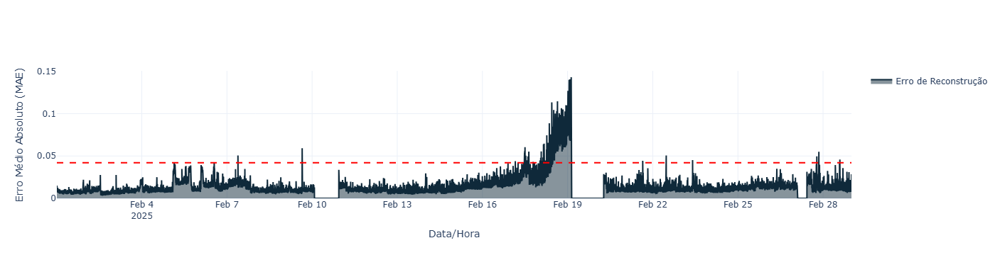

In [122]:
# Plot
def plot_predict(df_predict, threshold):
    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=df_predict.index,
        y=df_predict['loss'],
        mode='lines',
        name='Erro de Reconstrução',
        fill="tozeroy", 
        line=dict(color="#0F293A"),
        connectgaps=False
    ))
    
    fig.add_hline(
        y=threshold, 
        name='Limiar',
        line_dash="dash", 
        line_color="red", 
        line_width=2
    )
    
    fig.update_layout(
        xaxis_title='Data/Hora',
        yaxis_title='Erro Médio Absoluto (MAE)',
        template='plotly_white',
        hovermode="x unified",
        showlegend=True
    )

    return fig

fig = plot_predict(df_predict_tranad, calculated_pot_threshold)
fig.show()

In [123]:
fig.write_html("output/Detecção-TranAD_"+ process_name +".html")

## An Attention-Based ConvLSTM Autoencoder with Dynamic Thresholding for Unsupervised Anomaly Detection in Multivariate Time Series (ACLAE-DT) [Custo computacional alto]

Tayeh, T., Aburakhia, S., Myers, R., & Shami, A. (2022). An attention-based ConvLSTM autoencoder with dynamic thresholding for unsupervised anomaly detection in multivariate time series. Machine Learning and Knowledge Extraction, 4(2), 350-370.

In [ ]:
class ACLAEDataPreparer:
    def __init__(self, window_size=10, stride=1, batch_size=32):
        """
        Args:
            window_size (int): Tamanho da sequência temporal (T) para o ConvLSTM.
            stride (int): Passo da janela deslizante.
            batch_size (int): Tamanho do batch para o DataLoader.
        """
        self.window_size = window_size
        self.stride = stride
        self.batch_size = batch_size
        self.scaler = MinMaxScaler()

    def _create_sliding_windows(self, data):
        """
        Gera janelas deslizantes a partir da série temporal normalizada.
        Saída: (Num_Amostras, window_size, n_features)
        """
        n_samples, n_features = data.shape
        # Cálculo do número de janelas possíveis
        if n_samples < self.window_size:
            return np.array([])
            
        num_windows = (n_samples - self.window_size) // self.stride + 1
        
        # Usando stride_tricks para eficiência de memória (opcional) ou list comprehension simples
        windows = []
        for i in range(num_windows):
            start = i * self.stride
            end = start + self.window_size
            windows.append(data[start:end])
            
        return np.array(windows)

    def _construct_feature_images(self, sequences):
        """
        Converte sequências de vetores em sequências de imagens de características.
        [cite_start]Metodologia [cite: 271-283]: Produto interno par-a-par (Outer Product).
        
        Args:
            sequences: (Num_Amostras, Time, n_features)
        Returns:
            feature_images: (Num_Amostras, Time, 1, n_features, n_features)
        """
        if len(sequences) == 0:
            return torch.Tensor([])

        # Converter para tensor
        seq_tensor = torch.tensor(sequences, dtype=torch.float32)
        
        # Cálculo da Feature Image: Correlação entre pares (Outer Product)
        # 'bti,btj->btij': batch, time, feature_i * batch, time, feature_j
        feature_matrices = torch.einsum('bti,btj->btij', seq_tensor, seq_tensor)
        
        # Adiciona dimensão de canal (Channels=1)
        # Shape final: (Batch, Time, 1, Height=Features, Width=Features)
        feature_images = feature_matrices.unsqueeze(2)
        
        return feature_images

    def prepare_data(self, df_train, df_test):
        """
        Pipeline completo: Normaliza -> Janelas -> Feature Images -> DataLoaders.
        """
        print("--- Iniciando Preparação de Dados ---")
        
        # [cite_start]1. Normalização [cite: 241-244]
        # Ajusta o scaler apenas no treino para evitar data leakage
        train_data = self.scaler.fit_transform(df_train.values)
        test_data = self.scaler.transform(df_test.values)
        print(f"Dados normalizados. Features: {train_data.shape[1]}")

        # [cite_start]2. Enriquecimento com Janelas Deslizantes [cite: 250-254]
        X_train_seq = self._create_sliding_windows(train_data)
        X_test_seq = self._create_sliding_windows(test_data)
        print(f"Sequências geradas. Treino: {X_train_seq.shape}, Teste: {X_test_seq.shape}")

        # [cite_start]3. Construção das Imagens de Características [cite: 271-283]
        X_train_img = self._construct_feature_images(X_train_seq)
        X_test_img = self._construct_feature_images(X_test_seq)
        print(f"Feature Images construídas. Shape Treino: {X_train_img.shape}")

        # 4. Criação dos DataLoaders PyTorch
        if len(X_train_img) > 0:
            train_loader = DataLoader(TensorDataset(X_train_img), batch_size=self.batch_size, shuffle=True)
        else:
            train_loader = None
            
        if len(X_test_img) > 0:
            test_loader = DataLoader(TensorDataset(X_test_img), batch_size=self.batch_size, shuffle=False)
        else:
            test_loader = None
        
        return train_loader, test_loader, self.scaler

class ConvLSTMCell(nn.Module):
    def __init__(self, input_dim, hidden_dim, kernel_size, bias):
        super(ConvLSTMCell, self).__init__()
        
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        
        # Padding 'same' para manter as dimensões espaciais
        padding = kernel_size // 2
        
        self.conv = nn.Conv2d(in_channels=self.input_dim + self.hidden_dim,
                              out_channels=4 * self.hidden_dim,
                              kernel_size=kernel_size,
                              padding=padding,
                              bias=bias)

    def forward(self, input_tensor, cur_state):
        h_cur, c_cur = cur_state
        
        combined = torch.cat([input_tensor, h_cur], dim=1)
        combined_conv = self.conv(combined)
        cc_i, cc_f, cc_o, cc_g = torch.split(combined_conv, self.hidden_dim, dim=1)
        
        i = torch.sigmoid(cc_i)
        f = torch.sigmoid(cc_f)
        o = torch.sigmoid(cc_o)
        g = torch.tanh(cc_g)
        
        # [cite_start]Equações (7) a (12) do artigo [cite: 175-181]
        c_next = f * c_cur + i * g
        h_next = o * torch.tanh(c_next)
        
        return h_next, c_next

    def init_hidden(self, batch_size, image_size):
        height, width = image_size
        return (torch.zeros(batch_size, self.hidden_dim, height, width, device=self.conv.weight.device),
                torch.zeros(batch_size, self.hidden_dim, height, width, device=self.conv.weight.device))

class ConvLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim, kernel_size, num_layers, bias=True):
        super(ConvLSTM, self).__init__()
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.kernel_size = kernel_size
        self.bias = bias
        
        cell_list = []
        for i in range(self.num_layers):
            cur_input_dim = self.input_dim if i == 0 else self.hidden_dim[i-1]
            cell_list.append(ConvLSTMCell(input_dim=cur_input_dim,
                                          hidden_dim=self.hidden_dim[i],
                                          kernel_size=self.kernel_size[i],
                                          bias=self.bias))
        self.cell_list = nn.ModuleList(cell_list)

    def forward(self, input_tensor, hidden_state=None):
        b, t, _, h, w = input_tensor.size()
        
        if hidden_state is None:
            hidden_state = self._init_hidden(batch_size=b, image_size=(h, w))
            
        layer_output_list = []
        last_state_list = []
        
        seq_len = input_tensor.size(1)
        cur_layer_input = input_tensor
        
        for layer_idx in range(self.num_layers):
            h_c, c_c = hidden_state[layer_idx]
            output_inner = []
            
            for t in range(seq_len):
                h_c, c_c = self.cell_list[layer_idx](cur_layer_input[:, t, :, :, :], (h_c, c_c))
                output_inner.append(h_c)
            
            layer_output = torch.stack(output_inner, dim=1)
            cur_layer_input = layer_output
            
            layer_output_list.append(layer_output)
            last_state_list.append((h_c, c_c))
            
        return layer_output_list[-1], last_state_list

    def _init_hidden(self, batch_size, image_size):
        init_states = []
        for i in range(self.num_layers):
            init_states.append(self.cell_list[i].init_hidden(batch_size, image_size))
        return init_states

class BahdanauAttention(nn.Module):
    """
    [cite_start]Implementa as equações (16), (17), (18) do artigo [cite: 312-316].
    """
    def __init__(self, hidden_dim):
        super(BahdanauAttention, self).__init__()
        self.hidden_dim = hidden_dim
        self.attn = nn.Conv2d(self.hidden_dim * 2, self.hidden_dim, kernel_size=1) 
        self.v = nn.Conv2d(self.hidden_dim, 1, kernel_size=1)

    def forward(self, hidden, encoder_outputs):
        seq_len = encoder_outputs.size(1)
        batch_size = encoder_outputs.size(0)
        H, W = encoder_outputs.size(3), encoder_outputs.size(4)
        
        hidden_expanded = hidden.unsqueeze(1).repeat(1, seq_len, 1, 1, 1)
        
        encoder_outputs_flat = encoder_outputs.view(-1, self.hidden_dim, H, W)
        hidden_flat = hidden_expanded.view(-1, self.hidden_dim, H, W)
        
        combined = torch.cat((hidden_flat, encoder_outputs_flat), dim=1)
        energy = torch.tanh(self.attn(combined))
        attention_scores = self.v(energy)
        
        attention_scores = attention_scores.view(batch_size, seq_len, 1, H, W)
        alpha = F.softmax(attention_scores, dim=1)
        
        context_vector = (alpha * encoder_outputs).sum(dim=1)
        
        return context_vector

class ACLAE(nn.Module):
    def __init__(self, input_channels=1):
        super(ACLAE, self).__init__()
        
        # [cite_start]--- ENCODER [cite: 304, 306, 320-323] ---
        self.enc1 = ConvLSTM(input_dim=input_channels, hidden_dim=[64], kernel_size=[3], num_layers=1)
        self.pool1 = nn.MaxPool3d(kernel_size=(1, 2, 2), stride=(1, 2, 2)) 
        
        self.enc2 = ConvLSTM(input_dim=64, hidden_dim=[64], kernel_size=[3], num_layers=1)
        self.pool2 = nn.MaxPool3d(kernel_size=(1, 2, 2), stride=(1, 2, 2))
        
        self.enc3 = ConvLSTM(input_dim=64, hidden_dim=[32], kernel_size=[3], num_layers=1)
        
        # [cite_start]--- ATTENTION [cite: 308] ---
        self.attention = BahdanauAttention(hidden_dim=32)
        
        # [cite_start]--- DECODER [cite: 305, 306, 324-333] ---
        self.dec1_cell = ConvLSTMCell(input_dim=32, hidden_dim=32, kernel_size=3, bias=True)
        # Upsample pode ser problemático se as dimensões forem ímpares, mode 'nearest' é padrão
        
        self.dec2_cell = ConvLSTMCell(input_dim=32, hidden_dim=64, kernel_size=3, bias=True)
        
        self.dec3_cell = ConvLSTMCell(input_dim=64, hidden_dim=64, kernel_size=3, bias=True)
        
        self.final_conv = nn.Conv2d(64, input_channels, kernel_size=1)

    def forward(self, x):
        b, t, c, h, w = x.size()
        
        # --- ENCODER ---
        out_enc1, _ = self.enc1(x)
        out_pool1 = self.pool1(out_enc1.permute(0, 2, 1, 3, 4)).permute(0, 2, 1, 3, 4)
        
        out_enc2, _ = self.enc2(out_pool1)
        out_pool2 = self.pool2(out_enc2.permute(0, 2, 1, 3, 4)).permute(0, 2, 1, 3, 4)
        
        encoder_outputs, last_states_enc = self.enc3(out_pool2)
        
        # --- DECODER ---
        h_dec, c_dec = last_states_enc[0] 
        reconstructed_seq = []
        
        # Loop temporal para reconstrução
        for step in range(t):
            # 1. Atenção
            context = self.attention(h_dec, encoder_outputs)
            
            # 2. Decoder Layer 1
            h_dec, c_dec = self.dec1_cell(context, (h_dec, c_dec))
            d1_up = F.interpolate(h_dec, scale_factor=2, mode='nearest')
            
            # Inicialização Lazy para estados das próximas camadas
            if step == 0:
                self.h_d2 = torch.zeros(b, 64, d1_up.size(2), d1_up.size(3)).to(x.device)
                self.c_d2 = torch.zeros(b, 64, d1_up.size(2), d1_up.size(3)).to(x.device)
                
                d2_up_dummy = F.interpolate(self.h_d2, scale_factor=2, mode='nearest')
                self.h_d3 = torch.zeros(b, 64, d2_up_dummy.size(2), d2_up_dummy.size(3)).to(x.device)
                self.c_d3 = torch.zeros(b, 64, d2_up_dummy.size(2), d2_up_dummy.size(3)).to(x.device)
            
            # Decoder Layer 2
            self.h_d2, self.c_d2 = self.dec2_cell(d1_up, (self.h_d2, self.c_d2))
            d2_up = F.interpolate(self.h_d2, scale_factor=2, mode='nearest')
            
            # Decoder Layer 3
            self.h_d3, self.c_d3 = self.dec3_cell(d2_up, (self.h_d3, self.c_d3))
            
            # Output
            recon_img = self.final_conv(self.h_d3)
            reconstructed_seq.append(recon_img)
            
        reconstructed_tensor = torch.stack(reconstructed_seq, dim=1)
        
        # Resize final se necessário (caso pooling tenha cortado pixels ímpares)
        if reconstructed_tensor.size()[-2:] != x.size()[-2:]:
             reconstructed_tensor = F.interpolate(
                 reconstructed_tensor.view(-1, c, reconstructed_tensor.size(3), reconstructed_tensor.size(4)),
                 size=(h, w), mode='bilinear', align_corners=False
             ).view(b, t, c, h, w)

        return reconstructed_tensor

def compute_dynamic_threshold(model, train_loader, device, z=3):
    """
    Calcula o limiar dinâmico usando o dataset de treino (apenas dados normais).
    [cite_start]Eq 19 do artigo[cite: 365].
    """
    model.eval()
    all_errors = []
    
    print("Calculando Limiar Dinâmico...")
    with torch.no_grad():
        for batch in train_loader:
            inputs = batch[0].to(device)
            outputs = model(inputs)
            
            # Erro absoluto: |Original - Reconstruído|
            # Shape: (Batch, Time, 1, H, W) -> Média no tempo -> (Batch, 1, H, W)
            # O artigo sugere calcular o limiar para cada par de sensores (pixel)
            error = torch.abs(inputs - outputs).mean(dim=1) 
            all_errors.append(error.cpu())
            
    # Concatena todos os erros (N_Samples, 1, H, W)
    all_errors = torch.cat(all_errors, dim=0)
    
    # Calcula média e desvio padrão por PIXEL (por par de sensores)
    mu = torch.mean(all_errors, dim=0)
    sigma = torch.std(all_errors, dim=0)
    
    threshold_matrix = mu + z * sigma
    return threshold_matrix.to(device)

def evaluate_and_plot(model, test_loader, threshold_matrix, device):
    """
    Avalia o dataset de teste, calcula o score de anomalia (Razão Erro/Limiar)
    e plota o resultado temporal interativo usando Plotly.
    """
    model.eval()
    
    # Listas para armazenar a métrica de decisão de cada janela
    anomaly_scores = []
    
    print("Avaliando e Gerando Gráfico Interativo...")
    
    with torch.no_grad():
        for batch in test_loader:
            inputs = batch[0].to(device)
            outputs = model(inputs)
            
            # 1. Calcular o Erro de Reconstrução Médio no Tempo (Batch, 1, H, W)
            # A média é feita na dimensão temporal da janela
            error_test = torch.abs(inputs - outputs).mean(dim=1)
            
            # [cite_start]2. Calcular a Razão (Score) para cada pixel: Erro / Limiar [cite: 360-364]
            # Adicionamos um epsilon para evitar divisão por zero
            ratios = error_test / (threshold_matrix + 1e-8)
            
            # 3. O Score da Janela é a PIOR violação encontrada na matriz (Max Ratio)
            # Se o max_ratio da janela for > 1.0, ela é anômala
            batch_max_ratios, _ = torch.max(ratios.view(inputs.size(0), -1), dim=1)
            
            anomaly_scores.extend(batch_max_ratios.cpu().numpy())
            
    anomaly_scores = np.array(anomaly_scores)
    
    # --- Plotagem com Plotly ---
    fig = go.Figure()

    # 1. Linha principal (Score de Anomalia)
    fig.add_trace(go.Scatter(
        y=anomaly_scores,
        mode='lines',
        name='Score de Anomalia',
        line=dict(color='royalblue', width=1.5),
        hovertemplate='Janela: %{x}<br>Score: %{y:.4f}<extra></extra>'
    ))

    # 3. Linha de Limiar (Threshold = 1.0)
    fig.add_hline(
        y=1.0, 
        line_dash="dash", 
        line_color="red", 
        annotation_text="Limiar de Decisão (1.0)", 
        annotation_position="bottom right"
    )

    # Configurações de Layout
    fig.update_layout(
        title="<b>Detecção de Anomalias:</b> Razão (Erro / Limiar Dinâmico)",
        xaxis_title="Índice da Janela Temporal",
        yaxis_title="Score de Severidade (Razão Normalizada)",
        template="plotly_white",
        legend=dict(yanchor="top", y=0.99, xanchor="left", x=0.01),
        hovermode="x unified" # Facilita comparar valores no mesmo eixo X
    )
    fig.write_html("output/Detecção-ACLAE-DT_"+ process_name +".html")
    fig.show()
    
    return anomalies_indices

In [ ]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
WINDOW_SIZE = 10
STRIDE = 2
BATCH_SIZE = 128
N_FEATURES = df_train.shape[1]
EPOCHS = 5

print(f"Executando no dispositivo: {DEVICE}")

# --- Preparação ---
preparer = ACLAEDataPreparer(window_size=WINDOW_SIZE, stride=1, batch_size=BATCH_SIZE)
train_loader, test_loader, scaler = preparer.prepare_data(df_train, df_test)

if train_loader is None:
    print("Erro: Dados insuficientes para criar janelas.")
    exit()

# --- Instanciar Modelo ---
model = ACLAE(input_channels=1).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.MSELoss()

# --- Treinamento ---
print(f"--- Training {EPOCHS} epochs ---")
model.train()
for epoch in range(EPOCHS):
    total_loss = 0
    for batch in train_loader:
        inputs = batch[0].to(DEVICE)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, inputs)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
    
    avg_loss = total_loss / len(train_loader)
    print(f"Epoch {epoch+1}/{EPOCHS} | Loss: {avg_loss:.6f}")

# --- Cálculo do Limiar (Fase de Validação/Calibração) ---
threshold_matrix = compute_dynamic_threshold(model, train_loader, DEVICE, z=3)
print(f"Matriz de Limiar calculada. Shape: {threshold_matrix.shape}")

# --- Detecção no Teste ---
anomalous_indices = evaluate_and_plot(model, test_loader, threshold_matrix, DEVICE)

## Robust unsupervised anomaly detection via multi-time scale DCGANs with forgetting mechanism for industrial multivariate time series (MTS-DCGAN) [Resultado ruim modelo não convergiu]

Liang, H., Song, L., Wang, J., Guo, L., Li, X., & Liang, J. (2021). Robust unsupervised anomaly detection via multi-time scale DCGANs with forgetting mechanism for industrial multivariate time series. Neurocomputing, 423, 444-462.

In [ ]:
# Gerar matrizes de assinatura

class SignatureMatrixGenerator:
    def __init__(self, window_sizes=[10, 30, 60], forgetting_factor=0.9):
        """
        Gera matrizes de assinatura com mecanismo de esquecimento.
        Canais: 3 janelas com esquecimento + 1 janela base sem esquecimento.
        """
        self.window_sizes = window_sizes
        self.forgetting_factor = forgetting_factor
        
    def _calculate_weights(self, window_size, type='linear'):
        # Implementação do peso linear conforme Eq. (4) do artigo
        # f_l(t) = a + b * order(t). Assumindo a=0, b=0.9 normalizado ou similar.
        steps = np.arange(window_size)
        if type == 'linear':
            weights = steps / (window_size - 1) if window_size > 1 else np.ones(1)
            # Ajuste para garantir que o dado mais recente tenha peso maior
            weights = 0.1 + 0.9 * weights 
        elif type == 'exponential':
            # Eq. (5) alpha^order(t)
            alpha = 1.1
            weights = alpha ** steps
            weights = weights / weights.max()
        return weights.reshape(-1, 1)

    def compute_signature_matrix(self, segment, weights=None):
        """
        Calcula S = (X^T * X) / k normalizado para [-1, 1]
        Segmento shape: (window, n_features)
        """
        if weights is not None:
            # Aplica mecanismo de esquecimento: X_weighted = f(t) * X
            segment = segment * weights
            
        # Correlação (Dot product)
        # Transposta(X) * X
        matrix = np.dot(segment.T, segment)
        
        # Rescale factor k = w (conforme artigo)
        k = segment.shape[0]
        matrix = matrix / k
        
        # Normalize to [-1, 1] (Tanh range)
        # Simples min-max no range local ou global. 
        # O artigo diz "normalized to [-1, 1]". Faremos clip ou minmax local.
        max_val = np.max(np.abs(matrix))
        if max_val > 0:
            matrix = matrix / max_val
            
        return matrix

    def transform(self, data):
        """
        Transforma a série temporal (T, N) em (T-max_w, 4, N, N)
        """
        data = np.array(data)
        n_samples, n_features = data.shape
        max_w = max(self.window_sizes)
        
        signature_matrices = []
        
        # Loop pelas janelas deslizantes
        for t in range(max_w, n_samples):
            matrices_t = []
            
            # Canal 1, 2, 3: Diferentes escalas com Forgetting Mechanism
            for w in self.window_sizes:
                segment = data[t-w:t, :]
                weights = self._calculate_weights(w, type='linear')
                mat = self.compute_signature_matrix(segment, weights)
                matrices_t.append(mat)
            
            # Canal 4: Raw (Menor janela, sem esquecimento)
            w_raw = self.window_sizes[0]
            segment_raw = data[t-w_raw:t, :]
            mat_raw = self.compute_signature_matrix(segment_raw, weights=None)
            matrices_t.append(mat_raw)
            
            signature_matrices.append(np.stack(matrices_t)) # Shape (4, N, N)
            
        return np.array(signature_matrices)

In [ ]:
class Generator(nn.Module):
    def __init__(self, latent_dim, n_features):
        super(Generator, self).__init__()
        self.n_features = n_features
        self.init_size = n_features // 4 
        if self.init_size < 1: self.init_size = 1
        
        # Paper: "two fully connected layers"
        self.dense_layers = nn.Sequential(
            nn.Linear(latent_dim, 256), # Camada Densa 1
            nn.Tanh(),
            nn.Linear(256, 128 * self.init_size * self.init_size), # Camada Densa 2
            nn.Tanh()
        )
        
        self.conv_blocks = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.Tanh(),
            nn.ConvTranspose2d(64, 4, 4, stride=2, padding=1),
            nn.Tanh()
        )
        
        self.upsample_fix = nn.Upsample(size=(n_features, n_features), mode='bilinear', align_corners=True)

    def forward(self, z):
        out = self.dense_layers(z) # Passa pelas 2 camadas densas
        out = out.view(out.shape[0], 128, self.init_size, self.init_size)
        out = self.conv_blocks(out)
        out = self.upsample_fix(out)
        return out

class Discriminator(nn.Module):
    def __init__(self, n_features):
        super(Discriminator, self).__init__()
        
        # 2 Convolution Layers
        self.conv_blocks = nn.Sequential(
            nn.Conv2d(4, 64, 3, stride=2, padding=1),
            nn.Tanh(), # Artigo: Tanh nas intermediárias
            nn.Conv2d(64, 128, 3, stride=2, padding=1),
            nn.Tanh(),
        )
        
        # Calcula tamanho após convoluções para o Flatten
        # Com input N, stride 2, stride 2 -> N/4
        ds_size = n_features // 4
        if ds_size < 1: ds_size = 1
        self.flatten_dim = 128 * ds_size * ds_size
        
        # 2 Fully Connected Layers
        self.dense_blocks = nn.Sequential(
            nn.Flatten(),
            nn.Linear(self.flatten_dim, 100),
            nn.Tanh(),
            nn.Linear(100, 1),
            nn.Sigmoid() # Última camada Sigmoid
        )

    def forward(self, x):
        out = self.conv_blocks(x)
        out = self.dense_blocks(out)
        return out

In [ ]:
def train_mts_dcgan(df_train, epochs=20, batch_size=32, latent_dim=100, device='cpu'):
    # Preparar Dados
    scaler = MinMaxScaler(feature_range=(-1, 1))
    data_scaled = scaler.fit_transform(df_train.values)
    n_features = data_scaled.shape[1]
    
    # Gerar Matrizes de Assinatura
    print("Gerando Matrizes de Assinatura...")
    sig_gen = SignatureMatrixGenerator()
    X_train = sig_gen.transform(data_scaled)
    
    # DataLoader
    tensor_x = torch.Tensor(X_train)
    dataloader = DataLoader(TensorDataset(tensor_x), batch_size=batch_size, shuffle=True)
    
    # Inicializar Modelos
    generator = Generator(latent_dim, n_features).to(device)
    discriminator = Discriminator(n_features).to(device)
    
    # Otimizadores (SGD conforme artigo)
    # Learning rates: G=0.0004, D=0.0001
    opt_g = optim.SGD(generator.parameters(), lr=0.0004)
    opt_d = optim.SGD(discriminator.parameters(), lr=0.0001)
    
    criterion = nn.BCELoss()
    
    generator.train()
    discriminator.train()
    
    for epoch in range(epochs):
        for i, (real_imgs,) in enumerate(dataloader):
            real_imgs = real_imgs.to(device)
            batch_size = real_imgs.size(0)
            
            # Labels
            valid = torch.ones(batch_size, 1).to(device)
            fake = torch.zeros(batch_size, 1).to(device)
            
            # Treinar Generator
            opt_g.zero_grad()
            
            z = torch.randn(batch_size, latent_dim).to(device)
            gen_imgs = generator(z)
            
            # Loss do Gerador: tenta enganar o discriminador
            g_loss = criterion(discriminator(gen_imgs), valid)
            
            g_loss.backward()
            opt_g.step()
            
            #Treinar Discriminator
            opt_d.zero_grad()
            
            # Loss com imagens reais
            real_pred = discriminator(real_imgs)
            d_real_loss = criterion(real_pred, valid)
            
            # Loss com imagens falsas
            fake_pred = discriminator(gen_imgs.detach())
            d_fake_loss = criterion(fake_pred, fake)
            
            d_loss = (d_real_loss + d_fake_loss) / 2
            
            d_loss.backward()
            opt_d.step()
            
        print(f"[Epoch {epoch}/{epochs}] [D loss: {d_loss.item():.4f}] [G loss: {g_loss.item():.4f}]")
        
    return generator, discriminator, scaler, sig_gen

def detect_anomalies(df_test, generator, discriminator, scaler, sig_gen, threshold=None, device='cpu'):
    discriminator.eval()
    
    # Preprocessamento
    data_scaled = scaler.transform(df_test.values)
    X_test = sig_gen.transform(data_scaled)
    tensor_test = torch.Tensor(X_test).to(device)
    
    anomaly_scores = []
    
    with torch.no_grad():
        # O artigo define a pontuação baseada na saída do Discriminador.
        # D(x) -> 1 (Real/Normal), D(x) -> 0 (Fake/Anomalo).
        # Pontuação de anomalia = 1 - D(x) ou similar, para que anomalias tenham score alto.
        preds = discriminator(tensor_test)
        scores = 1 - preds.cpu().numpy().flatten()
        anomaly_scores = scores
        
    # Definição de Anomalias
    if threshold is None:
        # Se threshold não fornecido, calcular sobre o próprio teste (apenas exemplo)
        # Idealmente, usa-se threshold do treino
        threshold = np.mean(anomaly_scores) + 1 * np.std(anomaly_scores)
        
    predictions = (anomaly_scores > threshold).astype(int)
    
    return anomaly_scores, predictions

In [ ]:
EPOCHS = 10
BATCH_SIZE = 128
LATENT_DIM = 100
device = 'cuda' if torch.cuda.is_available() else 'cpu'

netG, netD, scaler, sig_gen = train_mts_dcgan(df_train, epochs=EPOCHS, batch_size=BATCH_SIZE, latent_dim=LATENT_DIM, device=device)

train_scores, _ = detect_anomalies(df_train, netG, netD, scaler, sig_gen, threshold=0, device=device)
threshold = np.mean(train_scores) + 1 * np.std(train_scores)
print(f"Limiar definido: {threshold}")

scores, preds = detect_anomalies(df_test, netG, netD, scaler, sig_gen, threshold=threshold, device=device)

In [ ]:
def plot_anomaly_loss(anomaly_scores, threshold, title="Detecção de Anomalias - Loss vs Limiar"):
    """
    Plota o score de anomalia (Loss), a linha de limiar e destaca os pontos anômalos.
    
    Args:
        anomaly_scores (array-like): Lista ou array com os scores de anomalia.
        threshold (float): Valor do limiar definido.
        title (str): Título do gráfico.
    """
    # Garantir que é um array numpy ou Series para indexação
    scores = np.array(anomaly_scores)
    indices = np.arange(len(scores))

    fig = go.Figure()

    # 1. Linha de Score (Loss)
    fig.add_trace(go.Scatter(
        x=eixoX_test, 
        y=scores,
        mode='lines',
        name='Anomaly Score',
        line=dict(color='blue', width=1.5),
        opacity=0.7
    ))

    # Linha do Limiar
    fig.add_hline(
        y=threshold,
        line_dash="dash",
        line_color="red"
    )

    # Layout
    fig.update_layout(
        title=title,
        xaxis_title="Tempo (Amostras)",
        yaxis_title="Score de Anomalia (Loss)",
        template="plotly_white",
        hovermode="x unified",
        legend=dict(yanchor="top", y=0.99, xanchor="left", x=0.01)
    )
    fig.write_html("output/Detecção-DCGANS_"+ process_name +".html")
    fig.show()

plot_anomaly_loss(scores, threshold)